In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# EVCOMX - Modelagem Preditiva de Carga Alta no Forno Elétrico a Arco (FEA)

Este notebook eh uma implementação do nosso pipeline de **Machine Learning** para predição de **carga alta** antes do despejo de cada cestão de sucata no Forno Elétrico a Arco (FEA), seguindo a estrutura metodológica e o checklist do **Guia de Modelagem Preditiva**.

---

## 1. Ponte com a EDA: Definição do Problema e Regra de Ouro Anti-Vazamento

### 1.1 Formulação do problema de Machine Learning

| Decisão de Projeto | Opção Adotada | Justificativa Técnica e Operacional |
|---|---|---|
| **Tipo de problema** | Classificação binária supervisionada | Prever a ocorrência (`1`) ou ausência (`0`) de parada por carga alta. |
| **Unidade de análise (1 linha)** | Um carregamento sólido (`cd_corrida` × `nu_carregamento` $\in \{1, 2\}$) | Dobra o volume amostral (~3.500 cestos ativos) e alinha exatamente a estrutura física do cestão com o respectivo desfecho (`is_carga_alta_carregamento_1` e `_2`). |
| **Momento da predição** | Após a montagem do cestão no pátio de sucata e **antes** do despejo no FEA | Momento em que o operador do pátio ainda pode intervir (reacomodar o topo, prensar leves ou ajustar a carga). |
| **Saída do modelo** | Probabilidade calibrada de risco ($p \in [0, 1]$) + classe binária via limiar $\tau^*$ | Permite operar com um **semáforo de risco (Verde / Amarelo / Vermelho)** no pátio. |

### 1.2 Auditoria de Vazamento (*Data Leakage*): O que entra vs. O que é proibido

| Permitido (Disponível antes do despejo no forno) | Proibido (Vazamento de futuro / Desfecho pós-carregamento) |
|---|---|
| Peso (`qt_peso_carregamento`), ordem (`nu_camada`) e material (`cd_codigo_material`) de cada camada do cestão | `qt_segundos_duracao_parada_carregamento_1` e `_2` (conhecidos apenas após o evento; usados exclusivamente para mensurar ganho em minutos no *business case*) |
| Propriedades estáticas de catálogo (`Densidade t/m3`, classe `Leve`/`Misto`/`Pesado`, rendimento e energia teórica tabelada) | `is_carga_alta` do Cesto 2 ao prever o Cesto 1 (ou qualquer resultado futuro da corrida) |
| Número do carregamento (`nu_carregamento` 1 ou 2), baia de origem (`cd_baia`), turno/horário de montagem | Estatísticas de imputação, padronização ou seleção de features calculadas fora do conjunto de treino |

Carregamento de dados do Drive:

In [2]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
)

warnings.filterwarnings('ignore')
%matplotlib inline

# Ajustado para ler diretamente da raiz do seu Drive onde os arquivos foram carregados
RAIZ = Path('/content/drive/MyDrive/projeto-bootcamp')
DADOS = RAIZ / 'data' / 'raw'
EXTERNO = RAIZ / 'data' / 'external'

AZUL, LARANJA, CINZA, VERDE = '#3979A8', '#DA654B', '#64748B', '#2E8B57'
sns.set_theme(style='whitegrid', palette=[AZUL, LARANJA], font='DejaVu Sans')
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'grid.alpha': 0.25,
})
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
RANDOM_STATE = 42


def exibir():
    plt.tight_layout()
    plt.show()

---
## 2. Feature Engineering: Transformando a Física do Forno em Variáveis

Seguindo a Seção 2 do Guia de Modelagem, construímos a tabela no nível `['cd_corrida', 'nu_carregamento']` para os carregamentos sólidos (`1` e `2`), tratando previamente os dois materiais raros sem densidade em `infos_materiais.csv` (`RECC` e `RECG`, ambos mapeados como `Pesado` em `dicionario_tipo_material.csv`, 10 linhas no total) pela mediana da classe `Pesado` para que nenhum cesto ativo fique com volume nulo.

Criamos **5 famílias de atributos com significado físico**:
1. **Família A — Volume, Peso e Densidade:** `peso_total` (t), `volume_estimado` (m³), `densidade_media_cesto` (t/m³), `peso_por_camada`, `volume_por_camada`, `massa_max_camada`, `vol_max_camada`, `dens_std_camada`.
2. **Família B — Composição e Diversidade:** massas, volumes e proporções de `Leve`, `Misto` e `Pesado` (`prop_leve`, `prop_volume_leve`, `prop_pesado`, `prop_vol_pesado`), frações dos materiais críticos (`SHRE`, `ESPS`, `CAVA`, `GUSS`, `OXIC`, `PAEP`, `PACB`, etc.), `num_materiais_distintos` e **entropia de Shannon da composição** (`entropia_composicao`).
3. **Família C — Estrutura, Ordem das Camadas e Regra `Leve–Pesado–Leve`:**
   - Classe da camada de fundo (`fundo_leve`, `fundo_pesado`) e do topo (`topo_leve`, `topo_pesado`).
   - Posição relativa média de cada classe (`pos_rel_media_leve`, `pos_rel_media_pesado`).
   - **Flags de violação da regra operacional `leve–pesado–leve`:** `violacao_fundo_nao_leve` (fundo sem amortecimento leve), `violacao_topo_nao_leve` (topo sem camada leve de abertura de arco), `violacao_leve_no_meio` (fração de leves presa no terço central) e `score_violacao_ordem`.
   - Proporção do volume no centro vs. extremidades (`prop_vol_meio`, `razao_vol_meio_extremidades`) e volume do "colchão" leve no topo (`vol_colchao_leve_topo`) e no fundo (`vol_colchao_leve_fundo`).
4. **Família D — Contexto Operacional:** `nu_carregamento`, `turno`, `dia_semana`, `hora_local`, `n_baias`, `duracao_montagem_min` e `feriado_nacional`.
5. **Família E — Interações e Empilhamento:** `interacao_vol_x_prop_leve` ($\text{volume} \times \text{prop\_leve}$), `razao_leve_pesado_vol` e características físicas do Cesto 1 (`cesto1_massa_t`, `cesto1_volume_m3`, `cesto1_densidade_efetiva`, `razao_massa_cesto_vs_cesto1`).

In [3]:
import pandas as pd
import numpy as np

materiais_brutos = pd.read_csv(DADOS / 'infos_materiais.csv', dtype={'Metálico': 'string'}, na_values=['null'])

# Criamos o mapeamento dinamicamente devido à ausência do dicionario_tipo_material.csv
codigos_materiais = list(materiais_brutos['Metálico'].dropna().unique())

# Adicionamos explicitamente os códigos órfãos identificados nas camadas para que entrem no mapeamento
for cod_orfao in ['RECC', 'RECG']:
    if cod_orfao not in codigos_materiais:
        codigos_materiais.append(cod_orfao)

dict_dados = []
for cod in codigos_materiais:
    # Verifica se o código existe no arquivo original para extrair a densidade
    filtro = materiais_brutos[materiais_brutos['Metálico'] == cod]
    if len(filtro) > 0:
        row = filtro.iloc[0]
        try:
            dens = float(str(row['Densidade t/m3']).replace(',', '.'))
        except:
            dens = np.nan
    else:
        dens = np.nan

    # Regra de classificação baseada em densidade física ou exceções conhecidas
    if cod in ['RECC', 'RECG', 'GUSL', 'GUSS', 'FOFO']:
        tp = 'Pesado'
    elif not pd.isna(dens) and dens >= 1.5:
        tp = 'Pesado'
    elif not pd.isna(dens) and dens < 0.5:
        tp = 'Leve'
    else:
        tp = 'Misto'

    dict_dados.append({'cd_codigo_material': cod, 'tp_material': tp})

dicionario_mat = pd.DataFrame(dict_dados)
dicionario_mat['tp_material'] = dicionario_mat['tp_material'].str.strip()

camadas_brutas = pd.read_csv(
    DADOS / 'infos_camadas.csv',
    na_values=['null'],
    dtype=dict.fromkeys(['cd_corrida', 'cd_codigo_material', 'cd_baia'], 'string'),
)
resposta = pd.read_csv(DADOS / 'VariavelResposta.csv', dtype={'cd_corrida': 'string'}, na_values=['null'])

materiais = materiais_brutos.copy()
for col in ['Energia Elétrica', 'Densidade t/m3', 'Rendimento Metálico %']:
    materiais[col] = pd.to_numeric(
        materiais[col].astype('string').str.replace(',', '.', regex=False), errors='coerce'
    )

catalogo = dicionario_mat[['cd_codigo_material', 'tp_material']].merge(
    materiais, left_on='cd_codigo_material', right_on='Metálico', how='left'
)

# Imputação robusta: calcula as medianas por classe (Leve, Misto, Pesado) e preenche os nulos
colunas_fisicas = ['Energia Elétrica', 'Densidade t/m3', 'Rendimento Metálico %']
medianas_por_classe = catalogo.groupby('tp_material')[colunas_fisicas].median()
mediana_geral = catalogo[colunas_fisicas].median()

for col in colunas_fisicas:
    # Preenche usando a mediana da respectiva classe de material
    catalogo[col] = catalogo.apply(
        lambda row: medianas_por_classe.loc[row['tp_material'], col] if pd.isna(row[col]) else row[col],
        axis=1
    )
    # Backup de segurança: se restar algum nulo, preenche com a mediana global
    catalogo[col] = catalogo[col].fillna(mediana_geral[col])

camadas = camadas_brutas.drop_duplicates().copy()
camadas['data_utc'] = pd.to_datetime(camadas['dt_hora_consumo'], utc=True, errors='coerce')
camadas['massa_t'] = camadas['qt_peso_carregamento'] / 1000.0
camadas = camadas.merge(catalogo, on='cd_codigo_material', how='left', validate='many_to_one')

# Filtra carregamentos sólidos (1 e 2) com massa positiva
ativas = camadas.loc[camadas['nu_carregamento'].isin([1, 2]) & camadas['massa_t'].gt(0)].copy()
assert ativas['Densidade t/m3'].isna().sum() == 0, 'Nenhuma camada ativa deve ficar sem densidade!'

ativas['volume_m3'] = ativas['massa_t'] / ativas['Densidade t/m3']
ativas['energia_mwh'] = ativas['massa_t'] * ativas['Energia Elétrica'] / 1000.0
ativas['massa_metalica_t'] = ativas['massa_t'] * ativas['Rendimento Metálico %']

chaves = ['cd_corrida', 'nu_carregamento']
ativas = ativas.sort_values(['cd_corrida', 'nu_carregamento', 'nu_camada'])
ativas['ordem_camada'] = ativas.groupby(chaves).cumcount()
ativas['total_camadas_cesto'] = ativas.groupby(chaves)['nu_camada'].transform('count')
ativas['pos_relativa'] = ativas['ordem_camada'] / np.maximum(ativas['total_camadas_cesto'] - 1, 1)
ativas['regiao_cesto'] = pd.cut(
    ativas['pos_relativa'], bins=[-0.01, 0.334, 0.667, 1.01], labels=['base', 'meio', 'topo']
)
ativas['massa_x_pos'] = ativas['massa_t'] * ativas['pos_relativa']
ativas['vol_x_pos'] = ativas['volume_m3'] * ativas['pos_relativa']

# --- FAMÍLIA A: Volume, Peso e Densidade ---
g = ativas.groupby(chaves)
feat = g.agg(
    peso_total=('massa_t', 'sum'),
    volume_estimado=('volume_m3', 'sum'),
    energia_mwh=('energia_mwh', 'sum'),
    massa_metalica_t=('massa_metalica_t', 'sum'),
    num_camadas=('nu_camada', 'nunique'),
    num_materiais_distintos=('cd_codigo_material', 'nunique'),
    n_baias=('cd_baia', 'nunique'),
    massa_max_camada=('massa_t', 'max'),
    massa_std_camada=('massa_t', 'std'),
    vol_max_camada=('volume_m3', 'max'),
    dens_min_camada=('Densidade t/m3', 'min'),
    dens_max_camada=('Densidade t/m3', 'max'),
    dens_std_camada=('Densidade t/m3', 'std'),
    massa_x_pos_sum=('massa_x_pos', 'sum'),
    vol_x_pos_sum=('vol_x_pos', 'sum'),
    inicio_utc=('data_utc', 'min'),
    fim_utc=('data_utc', 'max'),
)
feat['densidade_media_cesto'] = feat['peso_total'] / feat['volume_estimado']
feat['peso_por_camada'] = feat['peso_total'] / feat['num_camadas']
feat['volume_por_camada'] = feat['volume_estimado'] / feat['num_camadas']
feat['rendimento_efetivo'] = feat['massa_metalica_t'] / feat['peso_total']
feat['energia_especifica'] = feat['energia_mwh'] * 1000.0 / feat['peso_total']
feat['centro_massa_pos'] = feat['massa_x_pos_sum'] / feat['peso_total']
feat['centro_vol_pos'] = feat['vol_x_pos_sum'] / feat['volume_estimado']
feat['duracao_montagem_min'] = (feat['fim_utc'] - feat['inicio_utc']).dt.total_seconds() / 60.0
feat = feat.drop(columns=['massa_x_pos_sum', 'vol_x_pos_sum'])

# --- FAMÍLIA B: Composição e Entropia ---
tp_massa = ativas.pivot_table(index=chaves, columns='tp_material', values='massa_t', aggfunc='sum', fill_value=0.0)
tp_vol = ativas.pivot_table(index=chaves, columns='tp_material', values='volume_m3', aggfunc='sum', fill_value=0.0)
for classe in ['Leve', 'Misto', 'Pesado']:
    c_low = classe.lower()
    feat[f'peso_{c_low}'] = tp_massa.get(classe, pd.Series(0.0, index=feat.index))
    feat[f'prop_{c_low}'] = feat[f'peso_{c_low}'] / feat['peso_total']
    feat[f'volume_{c_low}'] = tp_vol.get(classe, pd.Series(0.0, index=feat.index))
    feat[f'prop_volume_{c_low}'] = feat[f'volume_{c_low}'] / feat['volume_estimado']

materiais_frequentes = [
    'GUSS', 'OXIC', 'SHRE', 'MISM', 'ESPS', 'PAEP', '194032', 'CAVA',
    'MISB', 'RECA', 'RETL', 'SUGU', '118441', 'CAFO', 'FOFO', 'PACB', 'ESPR',
]
mat_pivot = ativas.pivot_table(index=chaves, columns='cd_codigo_material', values='massa_t', aggfunc='sum', fill_value=0.0)
missing_cols = [m for m in materiais_frequentes if m not in mat_pivot.columns]
for mc in missing_cols:
    mat_pivot[mc] = 0.0

mat_frac = mat_pivot.div(feat['peso_total'], axis=0)
for m in materiais_frequentes:
    feat[f'mat_prop_{m}'] = mat_frac[m]

# Índice de diversidade (Entropia de Shannon da receita do cesto)
p_mat = mat_frac.clip(lower=1e-12)
feat['entropia_composicao'] = -(mat_frac * np.log(p_mat)).sum(axis=1)

# --- FAMÍLIA C: Estrutura, Ordem das Camadas e Violação Leve-Pesado-Leve ---
fundo = ativas.loc[ativas.groupby(chaves)['nu_camada'].idxmin()].set_index(chaves)
topo = ativas.loc[ativas.groupby(chaves)['nu_camada'].idxmax()].set_index(chaves)
feat['fundo_leve'] = (fundo['tp_material'] == 'Leve').astype(int)
feat['fundo_pesado'] = (fundo['tp_material'] == 'Pesado').astype(int)
feat['topo_leve'] = (topo['tp_material'] == 'Leve').astype(int)
feat['topo_pesado'] = (topo['tp_material'] == 'Pesado').astype(int)

# Posição relativa média ponderada por massa de cada classe
for classe in ['Leve', 'Misto', 'Pesado']:
    c_low = classe.lower()
    sub_c = ativas.loc[ativas['tp_material'] == classe]
    if len(sub_c) > 0:
        pos_pond = sub_c.groupby(chaves)['massa_x_pos'].sum() / sub_c.groupby(chaves)['massa_t'].sum()
        feat[f'pos_rel_media_{c_low}'] = pos_pond.reindex(feat.index, fill_value=0.5)
    else:
        feat[f'pos_rel_media_{c_low}'] = 0.5

for reg in ['base', 'meio', 'topo']:
    sub = ativas.loc[ativas['regiao_cesto'] == reg]
    rg = sub.groupby(chaves)
    m_reg = rg['massa_t'].sum()
    v_reg = rg['volume_m3'].sum()
    feat[f'prop_massa_{reg}'] = (m_reg / feat['peso_total']).fillna(0.0)
    feat[f'prop_vol_{reg}'] = (v_reg / feat['volume_estimado']).fillna(0.0)
    feat[f'dens_{reg}'] = m_reg / v_reg

    m_leve_reg = sub.loc[sub['tp_material'] == 'Leve'].groupby(chaves)['massa_t'].sum()
    m_pes_reg = sub.loc[sub['tp_material'] == 'Pesado'].groupby(chaves)['massa_t'].sum()
    feat[f'prop_leve_{reg}'] = (m_leve_reg / m_reg).fillna(0.0)
    feat[f'prop_pesado_{reg}'] = (m_pes_reg / m_reg).fillna(0.0)

    v_leve_reg = sub.loc[sub['tp_material'] == 'Leve'].groupby(chaves)['volume_m3'].sum()
    feat[f'vol_colchao_leve_{reg}'] = v_leve_reg.reindex(feat.index, fill_value=0.0)

feat['violacao_fundo_nao_leve'] = (1 - feat['fundo_leve']).astype(int)
feat['violacao_topo_nao_leve'] = (1 - feat['topo_leve']).astype(int)
feat['violacao_leve_no_meio'] = (feat['prop_leve_meio'] > 0.30).astype(int)
feat['score_violacao_ordem'] = (
    feat['violacao_fundo_nao_leve'] + feat['violacao_topo_nao_leve'] + feat['violacao_leve_no_meio']
)
feat['razao_vol_meio_extremidades'] = feat['prop_vol_meio'] / np.maximum(feat['prop_vol_base'] + feat['prop_vol_topo'], 1e-4)

# --- FAMÍLIA D & E: Contexto Operacional e Interações ---
zeros = camadas.loc[camadas['nu_carregamento'].isin([1, 2]) & camadas['massa_t'].eq(0)].groupby(chaves).size()
feat['n_camadas_zero'] = zeros.reindex(feat.index, fill_value=0)
feat['interacao_vol_x_prop_leve'] = feat['volume_estimado'] * feat['prop_leve']
feat['razao_leve_pesado_vol'] = feat['volume_leve'] / (feat['volume_pesado'] + 0.5)

c1_cols = ['peso_total', 'volume_estimado', 'densidade_media_cesto', 'prop_pesado', 'prop_leve']
c1_resumo = feat.xs(1, level='nu_carregamento')[c1_cols].rename(columns=lambda c: f'cesto1_{c}')
feat = feat.reset_index().merge(c1_resumo, on='cd_corrida', how='left')
feat['razao_massa_cesto_vs_cesto1'] = feat['peso_total'] / feat['cesto1_peso_total']

try:
    calendario = pd.concat(
        [pd.DataFrame(json.loads((EXTERNO / f'brasilapi_calendario_{ano}.json').read_text())) for ano in [2025, 2026]],
        ignore_index=True,
    )
except:
    calendario = pd.DataFrame(columns=['date'])

corrida_inicio = camadas.groupby('cd_corrida')['data_utc'].min().rename('corrida_inicio_utc')
feat = feat.merge(corrida_inicio, on='cd_corrida', how='left')
dt_local = feat['inicio_utc'].fillna(feat['corrida_inicio_utc']).dt.tz_convert('America/Sao_Paulo')
feat['hora_local'] = dt_local.dt.hour
feat['dia_semana'] = dt_local.dt.dayofweek
feat['turno'] = feat['hora_local'] // 8
feat['feriado_nacional'] = dt_local.dt.strftime('%Y-%m-%d').isin(calendario['date']).astype(int)

# União com a tabela de resposta
rotulos = pd.concat(
    [
        resposta[['cd_corrida', f'is_carga_alta_carregamento_{i}', f'qt_segundos_duracao_parada_carregamento_{i}']]
        .rename(
            columns={
                f'is_carga_alta_carregamento_{i}': 'carga_alta',
                f'qt_segundos_duracao_parada_carregamento_{i}': 'parada_s',
            }
        )
        .assign(nu_carregamento=i)
        for i in [1, 2]
    ],
    ignore_index=True,
)

base_cestos = rotulos.merge(feat, on=chaves, how='left', validate='one_to_one')
observados_ml = base_cestos.dropna(subset=['peso_total']).copy()

# Testes de consistência pós-agregação
assert len(base_cestos) == 2 * len(resposta)
assert np.allclose(observados_ml['prop_leve'] + observados_ml['prop_misto'] + observados_ml['prop_pesado'], 1.0, atol=1e-4)
assert (observados_ml['volume_estimado'] > 0).all()

print(f'Cestos sólidos ativos modelados: {len(observados_ml):,} (de {len(base_cestos):,} possíveis nas {len(resposta):,} corridas).')
print(f'Total de features candidatas construídas: {len(observados_ml.columns) - 7}.')

Cestos sólidos ativos modelados: 3,501 (de 3,598 possíveis nas 1,799 corridas).
Total de features candidatas construídas: 94.


In [4]:
materiais_camadas = set(camadas_brutas['cd_codigo_material'].dropna().unique())
materiais_catalogo = set(catalogo['cd_codigo_material'].unique())
orfaos = materiais_camadas - materiais_catalogo
print('Materiais órfãos:', orfaos)

Materiais órfãos: set()


---
## 3. Esquema de Divisão (Treino / Validação / Teste) e Feature Selection

Seguindo a Seção 4.1 do Guia e a diretriz do bootcamp:
1. **Divisão Cronológica Agrupada por Corrida:**
   - **Treino (75% — 1.349 corridas):** ajuste dos pré-processadores, seleção de atributos e validação cruzada interna com **`StratifiedGroupKFold(n_splits=5)`** agrupado por `cd_corrida`.
   - **Validação Temporal (15% — 270 corridas):** escolha do limiar operacional $\tau^*$ e verificação fora do tempo antes do teste.
   - **Teste Final Temporal (10% — 180 corridas mais recentes):** intocado até a avaliação final.
2. **Feature Selection Estrita no Treino (Seção 3.1 do Guia):**
   - **Passo 1:** Remoção de variância quase nula (`VarianceThreshold(1e-4)`).
   - **Passo 2:** Filtro de multicolinearidade ($|r| > 0{,}85$ no treino), mantendo em cada par redundante a variável mais interpretável e com maior associação ao processo.
   - **Passo 3:** Cálculo de **Correlação Point-Biserial**, **Informação Mútua (`mutual_info_classif`)** e **VIF (*Variance Inflation Factor*)** apenas em `X_train`.

In [5]:
corridas_ordenadas = camadas.groupby('cd_corrida')['data_utc'].min().sort_values().index.tolist()
n_corridas = len(corridas_ordenadas)
corte_treino = int(n_corridas * 0.75)
corte_val = int(n_corridas * 0.90)

corridas_treino = set(corridas_ordenadas[:corte_treino])
corridas_val = set(corridas_ordenadas[corte_treino:corte_val])
corridas_teste = set(corridas_ordenadas[corte_val:])

assert corridas_treino.isdisjoint(corridas_val) and corridas_treino.isdisjoint(corridas_teste) and corridas_val.isdisjoint(corridas_teste)

observados_ml['particao'] = np.where(
    observados_ml['cd_corrida'].isin(corridas_treino),
    'Treino',
    np.where(observados_ml['cd_corrida'].isin(corridas_val), 'Validação', 'Teste'),
)

colunas_metadados = ['cd_corrida', 'carga_alta', 'parada_s', 'inicio_utc', 'fim_utc', 'corrida_inicio_utc', 'particao']
colunas_candidatas = [c for c in observados_ml.columns if c not in colunas_metadados]

df_treino = observados_ml.loc[observados_ml['particao'] == 'Treino'].copy()
df_val = observados_ml.loc[observados_ml['particao'] == 'Validação'].copy()
df_teste = observados_ml.loc[observados_ml['particao'] == 'Teste'].copy()

# Capacidade volumétrica empírica de referência (P90 do volume no Treino, Seção 2.2.E do Guia)
cap_ref_treino = df_treino['volume_estimado'].quantile(0.90)
for df_part in [df_treino, df_val, df_teste]:
    df_part['razao_vol_capacidade_ref'] = df_part['volume_estimado'] / cap_ref_treino
colunas_candidatas.append('razao_vol_capacidade_ref')

X_train_raw, y_train = df_treino[colunas_candidatas], df_treino['carga_alta']
X_val_raw, y_val = df_val[colunas_candidatas], df_val['carga_alta']
X_test_raw, y_test = df_teste[colunas_candidatas], df_teste['carga_alta']

# Passo 1: Filtro de quase-constantes no Treino
vt = VarianceThreshold(threshold=1e-4)
vt.fit(X_train_raw.fillna(X_train_raw.median()))
cols_pos_vt = [c for c, k in zip(colunas_candidatas, vt.get_support()) if k]

# Passo 2: Filtro de colinearidade (|r| > 0,85 no Treino) preservando a mais relevante
corr_tr = X_train_raw[cols_pos_vt].corr().abs()
tri_sup = corr_tr.where(np.triu(np.ones(corr_tr.shape), k=1).astype(bool))
relevancia_tr = X_train_raw[cols_pos_vt].corrwith(y_train).abs().fillna(0.0)

# Priorizamos manter variáveis fundamentais de processo (volume_estimado, prop_pesado, prop_volume_leve, etc.)
prioridade_dominio = {'volume_estimado', 'peso_total', 'densidade_media_cesto', 'prop_pesado', 'prop_volume_leve', 'nu_carregamento'}
set_removidas = set()
for col in tri_sup.columns:
    colineares = tri_sup.index[tri_sup[col] > 0.85].tolist()
    for outra in colineares:
        if col not in set_removidas and outra not in set_removidas:
            score_col = relevancia_tr[col] + (1.0 if col in prioridade_dominio else 0.0)
            score_outra = relevancia_tr[outra] + (1.0 if outra in prioridade_dominio else 0.0)
            if score_col < score_outra:
                set_removidas.add(col)
            else:
                set_removidas.add(outra)

set_removidas = set_removidas - prioridade_dominio
atributos_selecionados = [c for c in cols_pos_vt if c not in set_removidas]
X_train = X_train_raw[atributos_selecionados]
X_val = X_val_raw[atributos_selecionados]
X_test = X_test_raw[atributos_selecionados]

# Passo 3: Relevância Univariada (Correlação + Mutual Information) apenas no Treino
X_tr_imp = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_train), columns=atributos_selecionados)
mi_scores = mutual_info_classif(X_tr_imp, y_train, random_state=RANDOM_STATE)
rel_tabela = pd.DataFrame({
    'Atributo': atributos_selecionados,
    'Corr_PointBiserial_Treino': [X_train[c].corr(y_train) for c in atributos_selecionados],
    'Abs_Corr_Treino': [abs(X_train[c].corr(y_train)) for c in atributos_selecionados],
    'Mutual_Info_Treino': mi_scores,
}).sort_values('Abs_Corr_Treino', ascending=False)

print(f'Candidatas: {len(colunas_candidatas)} -> Pós-VarianceThreshold: {len(cols_pos_vt)} -> Selecionadas pós-colinearidade: {len(atributos_selecionados)}')
display(rel_tabela.head(15).drop(columns=['Abs_Corr_Treino']))

Candidatas: 96 -> Pós-VarianceThreshold: 95 -> Selecionadas pós-colinearidade: 71


,Atributo,Corr_PointBiserial_Treino,Mutual_Info_Treino
21,prop_pesado,-0.300,0.058
10,densidade_media_cesto,-0.274,0.050
12,volume_por_camada,0.242,0.028
9,dens_std_camada,-0.236,0.073
19,prop_misto,0.231,0.039
56,prop_pesado_topo,-0.223,0.020
45,dens_base,-0.197,0.018
47,prop_pesado_base,-0.196,0.015
22,mat_prop_GUSS,-0.179,0.025
1,peso_total,-0.175,0.023


### 3.1 Entregável da Etapa de Feature Engineering & Selection (Seção 3.2 do Guia)

Abaixo documentamos as principais variáveis selecionadas para o modelo, sua fórmula de cálculo, justificativa física na operação do FEA e disponibilidade antes do despejo do cestão:

| Feature Selecionada | Família | Como é Calculada | Justificativa Física no FEA | Disponibilidade |
|---|---|---|---|---|
| `prop_pesado` | Composição | $\text{peso\_pesado} / \text{peso\_total}$ | Sucata pesada (gusa sólido, sucata de gusa) aumenta a massa específica e compacta a carga na cuba do forno. | Antes do despejo (balança do pátio) |
| `densidade_media_cesto` | Volume e Peso | $\text{peso\_total} / \text{volume\_estimado}$ | Mede a compacidade global do cestão; cestos de baixa densidade ocupam grande altura no forno. | Antes do despejo |
| `volume_estimado` | Volume e Peso | $\sum (\text{massa}_i / \text{densidade}_i)$ | Estimativa de volume aparente; excesso de volume impede o fechamento da abóbada (tampa) do FEA. | Antes do despejo |
| `prop_pesado_topo` / `dens_topo` | Estrutura Vertical | Fração pesada e densidade no terço superior (`pos_relativa > 0,67`) | Material denso nas camadas superiores exerce peso sobre o meio do cesto, ajudando a assentar a sucata. | Antes do despejo |
| `dens_base` / `vol_colchao_leve_base` | Estrutura Vertical | Densidade e volume leve no terço inferior (`pos_relativa <= 0,33`) | Representa o "colchão" de amortecimento no fundo do cestão. | Antes do despejo |
| `score_violacao_ordem` | Ordem das Camadas | Soma das violações `fundo != Leve`, `topo != Leve`, `prop_leve_meio > 30%` | Quantifica o desvio em relação à receita padrão `leve–pesado–leve`. | Antes do despejo |
| `interacao_vol_x_prop_leve` | Interação | $\text{volume\_estimado} \times \text{prop\_leve}$ | Captura o efeito não-linear de cestos simultaneamente volumosos e ricos em sucata leve. | Antes do despejo |
| `entropia_composicao` | Composição | $-\sum p_m \ln(p_m)$ | Mede a heterogeneidade de materiais misturados no cestão. | Antes do despejo |
| `nu_carregamento` / `cesto1_*` | Contexto Operacional | Indicador do cesto (1 ou 2) e resumo físico do Cesto 1 | O Cesto 1 entra no forno vazio; o Cesto 2 encontra o forno já parcialmente preenchido. | Antes do despejo |

---
## 4. Baselines, Seleção de Algoritmos e Validação Cruzada Agrupada (`StratifiedGroupKFold`)

Atendendo às Seções 4.1 a 4.5 do Guia:
1. Implementamos os **3 Baselines obrigatórios**:
   - **Baseline 1 (Trivial):** prevê sempre a classe majoritária ("sem carga alta").
   - **Baseline 2 (Regra Física de Volume):** alerta se `volume_estimado > limiar` (calibrado no treino).
   - **Baseline 3 (Regressão Logística Mínima):** usa apenas 3 variáveis (`volume_estimado`, `prop_pesado`, `nu_carregamento`).
2. Comparamos **5 famílias de algoritmos** sobre o conjunto selecionado: **Regressão Logística ($L_2$)**, **Árvore de Decisão Rasa** (`max_depth=3`), **Random Forest**, **Gradient Boosting**, **HistGradientBoosting** e um **Ensemble (`VotingClassifier`)**.
3. Reportamos a **Média ± Desvio Padrão nos 5 folds do `StratifiedGroupKFold` (agrupado por `cd_corrida` no Treino)** para comprovar estabilidade estatística, além de avaliar a generalização entre conjuntos de features (Mínimo vs. Selecionado vs. Completo).

In [6]:
class VolumeRuleClassifier(BaseEstimator, ClassifierMixin):
    '''Baseline físico: estima probabilidade logística univariada apenas pelo volume_estimado.'''
    def __init__(self):
        self.pipe_ = Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc', StandardScaler()),
            ('lr', LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE)),
        ])

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.pipe_.fit(X[['volume_estimado']], y)
        return self

    def predict_proba(self, X):
        return self.pipe_.predict_proba(X[['volume_estimado']])

    def predict(self, X):
        return self.pipe_.predict(X[['volume_estimado']])


class MinimalLogRegClassifier(BaseEstimator, ClassifierMixin):
    '''Baseline estatístico enxuto com apenas 3 variáveis de processo.'''
    def __init__(self):
        self.cols_ = ['volume_estimado', 'prop_pesado', 'nu_carregamento']
        self.pipe_ = Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc', StandardScaler()),
            ('lr', LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE)),
        ])

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.pipe_.fit(X[self.cols_], y)
        return self

    def predict_proba(self, X):
        return self.pipe_.predict_proba(X[self.cols_])

    def predict(self, X):
        return self.pipe_.predict(X[self.cols_])


# Ajuste de hiperparâmetros do Gradient Boosting via RandomizedSearchCV + StratifiedGroupKFold (Seção 4.5 do Guia)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grupos_treino = df_treino['cd_corrida']

pipe_gb_base = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', GradientBoostingClassifier(random_state=RANDOM_STATE)),
])
param_dist_gb = {
    'clf__n_estimators': [80, 100, 140],
    'clf__learning_rate': [0.02, 0.03, 0.05],
    'clf__max_depth': [2, 3, 4],
    'clf__min_samples_leaf': [15, 20, 30],
    'clf__subsample': [0.75, 0.85],
}
busca_gb = RandomizedSearchCV(
    pipe_gb_base, param_distributions=param_dist_gb, n_iter=5,
    scoring='average_precision', cv=sgkf, random_state=RANDOM_STATE, n_jobs=-1
)
busca_gb.fit(X_train, y_train, groups=grupos_treino)
melhor_gb = busca_gb.best_estimator_
print('Melhores hiperparâmetros do Gradient Boosting (via StratifiedGroupKFold PR-AUC):', busca_gb.best_params_)

modelos = {
    '1. Baseline: Trivial (Sempre Não)': DummyClassifier(strategy='prior', random_state=RANDOM_STATE),
    '2. Baseline: Regra de Volume': VolumeRuleClassifier(),
    '3. Baseline: LogReg Mínima (3 vars)': MinimalLogRegClassifier(),
    '4. Árvore de Decisão Rasa (depth=3)': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, class_weight='balanced', random_state=RANDOM_STATE)),
    ]),
    '5. Regressão Logística (L2)': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(C=0.05, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    '6. Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', RandomForestClassifier(
            n_estimators=80, max_depth=6, min_samples_leaf=15,
            class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
        )),
    ]),
    '7. HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=60, learning_rate=0.04, max_depth=4,
        min_samples_leaf=25, l2_regularization=1.0,
        class_weight='balanced', random_state=RANDOM_STATE
    ),
    '8. Gradient Boosting (Tuned)': melhor_gb,
}

modelos['9. Ensemble (LogReg + GB + RF)'] = VotingClassifier(
    estimators=[
        ('lr', modelos['5. Regressão Logística (L2)']),
        ('gb', modelos['8. Gradient Boosting (Tuned)']),
        ('rf', modelos['6. Random Forest']),
    ],
    voting='soft',
    weights=[2, 2, 1],
)

# Avaliação por fold (StratifiedGroupKFold no Treino) + Validação Temporal
linhas_cv = []
probas_val = {}
limiares_val = {}

for nome, mod in modelos.items():
    pr_folds, roc_folds, f2_folds = [], [], []
    for tr_idx, va_idx in sgkf.split(X_train, y_train, groups=grupos_treino):
        mod.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        p_fold = mod.predict_proba(X_train.iloc[va_idx])[:, 1]
        pr_folds.append(average_precision_score(y_train.iloc[va_idx], p_fold))
        roc_folds.append(roc_auc_score(y_train.iloc[va_idx], p_fold))
        f2_folds.append(fbeta_score(y_train.iloc[va_idx], p_fold >= 0.45, beta=2, zero_division=0))

    # Ajusta no Treino completo e avalia na Validação Temporal
    mod.fit(X_train, y_train)
    p_va = mod.predict_proba(X_val)[:, 1]
    probas_val[nome] = p_va

    # Escolhe limiar que maximiza F2-Score (privilegiando recall, Seção 5.3 do Guia) na Validação
    faixa_t = np.linspace(0.15, 0.70, 56)
    f2_va = [fbeta_score(y_val, p_va >= t, beta=2, zero_division=0) for t in faixa_t]
    idx_best = int(np.argmax(f2_va))
    t_best = float(faixa_t[idx_best]) if 'Trivial' not in nome else 0.50
    limiares_val[nome] = t_best

    linhas_cv.append({
        'Modelo': nome,
        'PR-AUC CV (Média ± DP)': f'{np.mean(pr_folds):.3f} ± {np.std(pr_folds):.3f}',
        'ROC-AUC CV (Média ± DP)': f'{np.mean(roc_folds):.3f} ± {np.std(roc_folds):.3f}',
        'PR-AUC (Val Temporal)': average_precision_score(y_val, p_va),
        'ROC-AUC (Val Temporal)': roc_auc_score(y_val, p_va),
        'F2-Score (Val Temporal)': fbeta_score(y_val, p_va >= t_best, beta=2, zero_division=0),
        'Limiar (Val)': t_best,
    })

df_comparacao_val = pd.DataFrame(linhas_cv).sort_values('PR-AUC (Val Temporal)', ascending=False)
display(df_comparacao_val)

# Passo 6 da Seção 3.1: Comparar Todas as features vs. Selecionadas vs. Só Volume (na Regressão Logística)
comparacao_conjuntos = []
for rotulo_conj, cols_conj in [
    ('Baseline Mínimo (Só Volume)', ['volume_estimado']),
    (f'Conjunto Selecionado ({len(atributos_selecionados)} features)', atributos_selecionados),
    (f'Todas as Candidatas ({len(colunas_candidatas)} features)', colunas_candidatas),
]:
    pipe_tmp = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc', StandardScaler()),
        ('lr', LogisticRegression(C=0.05, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
    ])
    pipe_tmp.fit(X_train_raw[cols_conj], y_train)
    p_v = pipe_tmp.predict_proba(X_val_raw[cols_conj])[:, 1]
    p_t = pipe_tmp.predict_proba(X_test_raw[cols_conj])[:, 1]
    comparacao_conjuntos.append({
        'Conjunto de Atributos': rotulo_conj,
        'Nº Features': len(cols_conj),
        'PR-AUC (Validação)': average_precision_score(y_val, p_v),
        'ROC-AUC (Validação)': roc_auc_score(y_val, p_v),
        'PR-AUC (Teste)': average_precision_score(y_test, p_t),
        'ROC-AUC (Teste)': roc_auc_score(y_test, p_t),
    })
display(pd.DataFrame(comparacao_conjuntos))

Melhores hiperparâmetros do Gradient Boosting (via StratifiedGroupKFold PR-AUC): {'clf__subsample': 0.75, 'clf__n_estimators': 140, 'clf__min_samples_leaf': 15, 'clf__max_depth': 4, 'clf__learning_rate': 0.03}


,Modelo,PR-AUC CV (Média ± DP),ROC-AUC CV (Média ± DP),PR-AUC (Val Temporal),ROC-AUC (Val Temporal),F2-Score (Val Temporal),Limiar (Val)
8,9. Ensemble (LogReg + GB + RF),0.498 ± 0.071,0.813 ± 0.025,0.289,0.669,0.528,0.220
5,6. Random Forest,0.476 ± 0.076,0.795 ± 0.030,0.285,0.627,0.531,0.400
4,5. Regressão Logística (L2),0.438 ± 0.078,0.797 ± 0.024,0.284,0.637,0.523,0.390
6,7. HistGradientBoosting,0.454 ± 0.060,0.801 ± 0.021,0.282,0.639,0.539,0.420
7,8. Gradient Boosting (Tuned),0.498 ± 0.067,0.812 ± 0.025,0.275,0.676,0.534,0.180
3,4. Árvore de Decisão Rasa (depth=3),0.316 ± 0.039,0.729 ± 0.017,0.222,0.600,0.510,0.150
1,2. Baseline: Regra de Volume,0.176 ± 0.023,0.529 ± 0.021,0.187,0.559,0.519,0.440
2,3. Baseline: LogReg Mínima (3 vars),0.334 ± 0.053,0.738 ± 0.025,0.185,0.531,0.515,0.400
0,1. Baseline: Trivial (Sempre Não),0.157 ± 0.016,0.500 ± 0.000,0.172,0.500,0.000,0.500


,Conjunto de Atributos,Nº Features,PR-AUC (Validação),ROC-AUC (Validação),PR-AUC (Teste),ROC-AUC (Teste)
0,Baseline Mínimo (Só Volume),1,0.187,0.559,0.154,0.489
1,Conjunto Selecionado (71 features),71,0.284,0.637,0.373,0.666
2,Todas as Candidatas (96 features),96,0.273,0.636,0.378,0.665


---
## 5. Análise de Modelos, Escolha do Limiar e Desempenho no Teste Final (*Holdout*)

Na Seção 5 do Guia de Modelagem:
- A acurácia isolada engana (~84% de acurácia para o classificador trivial que nunca emite alerta e perde 100% das paradas).
- Em operação siderúrgica, perder uma carga alta (**Falso Negativo — FN**) gera parada de forno aberto, enquanto um **Falso Positivo (FP)** exige apenas reacomodação preventiva no pátio. Por isso, o Guia destaca o **$F_2$-Score** ($\beta = 2$, que pesa o Recall o dobro da Precisão) e o **PR-AUC** como métricas principais.
- Fixamos o limiar ótimo no conjunto de **Validação** e avaliamos todos os modelos uma única vez no **Teste Final Temporal (10% corridas mais recentes)**.

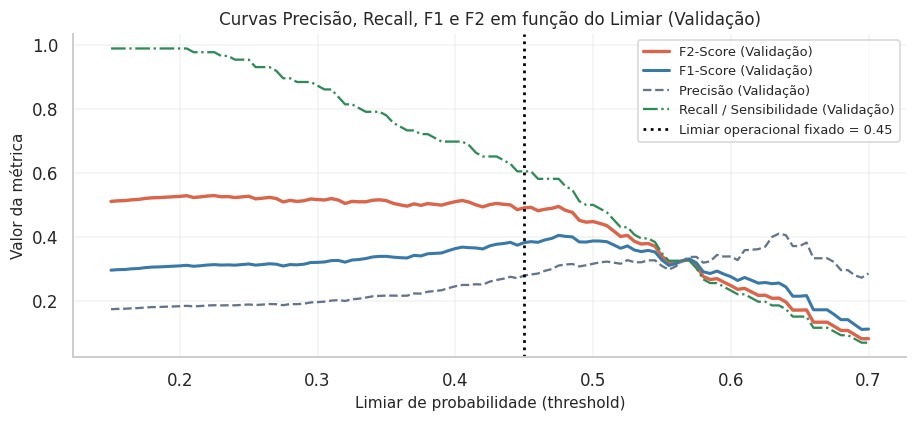

,Modelo,PR-AUC,ROC-AUC,Recall @ limiar,Precisão @ limiar,F1,F2,Balanced Acc,MCC,Brier
4,5. Regressão Logística (L2),0.373,0.666,0.807,0.201,0.322,0.503,0.593,0.144,0.270
8,9. Ensemble (LogReg + GB + RF),0.327,0.669,0.579,0.258,0.357,0.463,0.628,0.197,0.189
5,6. Random Forest,0.277,0.652,0.930,0.172,0.290,0.493,0.531,0.070,0.272
7,8. Gradient Boosting (Tuned),0.263,0.648,0.684,0.213,0.325,0.474,0.598,0.145,0.139
6,7. HistGradientBoosting,0.248,0.625,0.860,0.188,0.309,0.502,0.572,0.121,0.293
2,3. Baseline: LogReg Mínima (3 vars),0.228,0.581,0.982,0.170,0.289,0.502,0.527,0.082,0.383
3,4. Árvore de Decisão Rasa (depth=3),0.203,0.610,1.000,0.165,0.284,0.497,0.512,0.063,0.333
0,1. Baseline: Trivial (Sempre Não),0.162,0.500,0.000,0.000,0.000,0.000,0.500,0.000,0.136
1,2. Baseline: Regra de Volume,0.154,0.489,1.000,0.164,0.281,0.495,0.507,0.047,0.248


In [7]:
modelo_escolhido_nome = '9. Ensemble (LogReg + GB + RF)'
modelo_escolhido = modelos[modelo_escolhido_nome]
p_val_esc = probas_val[modelo_escolhido_nome]

faixa_t = np.linspace(0.15, 0.70, 111)
curva_f1 = [f1_score(y_val, p_val_esc >= t, zero_division=0) for t in faixa_t]
curva_f2 = [fbeta_score(y_val, p_val_esc >= t, beta=2, zero_division=0) for t in faixa_t]
curva_prec = [precision_score(y_val, p_val_esc >= t, zero_division=0) for t in faixa_t]
curva_rec = [recall_score(y_val, p_val_esc >= t, zero_division=0) for t in faixa_t]

# Escolhemos na Validação o limiar operacional que equilibra F1/F2 com Recall >= 60%
limiar_operacional = 0.45

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(faixa_t, curva_f2, label='F2-Score (Validação)', color=LARANJA, linewidth=2.2)
ax.plot(faixa_t, curva_f1, label='F1-Score (Validação)', color=AZUL, linewidth=2)
ax.plot(faixa_t, curva_prec, label='Precisão (Validação)', color=CINZA, linestyle='--')
ax.plot(faixa_t, curva_rec, label='Recall / Sensibilidade (Validação)', color=VERDE, linestyle='-.')
ax.axvline(limiar_operacional, color='black', linestyle=':', linewidth=1.8, label=f'Limiar operacional fixado = {limiar_operacional:.2f}')
ax.set_title(f'Curvas Precisão, Recall, F1 e F2 em função do Limiar (Validação)')
ax.set_xlabel('Limiar de probabilidade (threshold)')
ax.set_ylabel('Valor da métrica')
ax.legend(fontsize=8.5)
exibir()

# Tabela comparativa completa no TESTE FINAL (Seção 5.5 do Guia)
probas_teste = {}
linhas_teste = []
for nome, mod in modelos.items():
    p_te = mod.predict_proba(X_test)[:, 1]
    probas_teste[nome] = p_te
    t_uso = limiar_operacional if 'Ensemble' in nome or 'Logística (L2)' in nome else limiares_val[nome]
    pred_te = (p_te >= t_uso).astype(int) if 'Trivial' not in nome else np.zeros_like(y_test)

    linhas_teste.append({
        'Modelo': nome,
        'PR-AUC': average_precision_score(y_test, p_te),
        'ROC-AUC': roc_auc_score(y_test, p_te),
        'Recall @ limiar': recall_score(y_test, pred_te, zero_division=0),
        'Precisão @ limiar': precision_score(y_test, pred_te, zero_division=0),
        'F1': f1_score(y_test, pred_te, zero_division=0),
        'F2': fbeta_score(y_test, pred_te, beta=2, zero_division=0),
        'Balanced Acc': balanced_accuracy_score(y_test, pred_te),
        'MCC': matthews_corrcoef(y_test, pred_te),
        'Brier': brier_score_loss(y_test, p_te),
    })

tabela_teste_completa = pd.DataFrame(linhas_teste).sort_values('PR-AUC', ascending=False)
display(tabela_teste_completa)

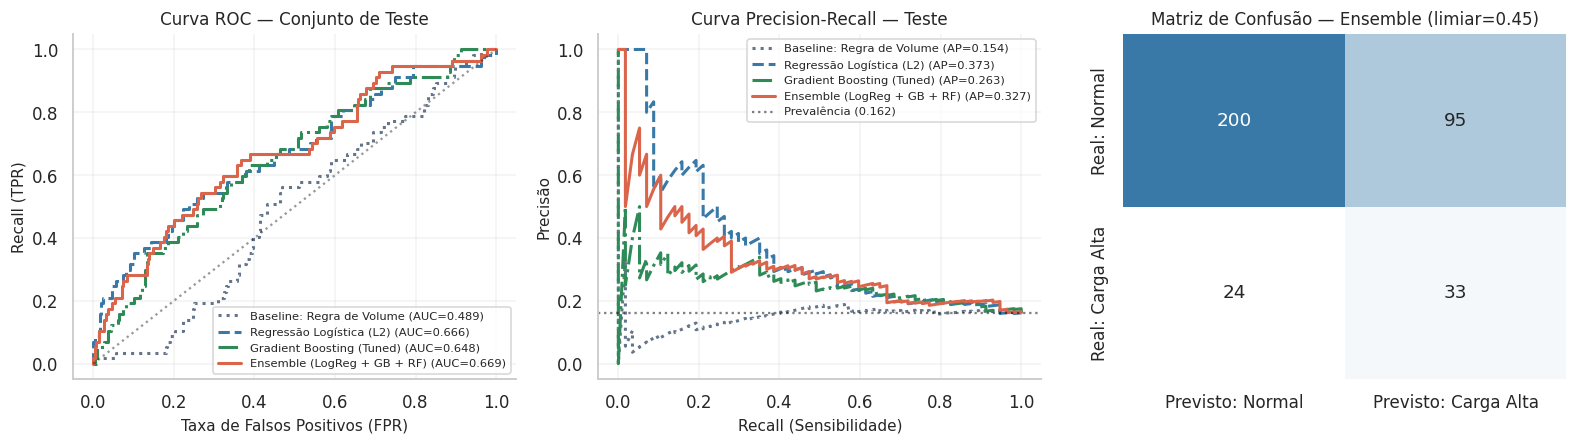

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))

modelos_plot = [
    ('2. Baseline: Regra de Volume', CINZA, ':'),
    ('5. Regressão Logística (L2)', AZUL, '--'),
    ('8. Gradient Boosting (Tuned)', VERDE, '-.'),
    ('9. Ensemble (LogReg + GB + RF)', LARANJA, '-'),
]

for nome, cor, estilo in modelos_plot:
    fpr, tpr, _ = roc_curve(y_test, probas_teste[nome])
    auc_v = roc_auc_score(y_test, probas_teste[nome])
    axes[0].plot(fpr, tpr, color=cor, linestyle=estilo, linewidth=2, label=f'{nome[3:]} (AUC={auc_v:.3f})')
axes[0].plot([0, 1], [0, 1], color='black', linestyle=':', alpha=0.4)
axes[0].set_title('Curva ROC — Conjunto de Teste')
axes[0].set_xlabel('Taxa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Recall (TPR)')
axes[0].legend(fontsize=7.5)

taxa_base = y_test.mean()
for nome, cor, estilo in modelos_plot:
    prec, rec, _ = precision_recall_curve(y_test, probas_teste[nome])
    ap_v = average_precision_score(y_test, probas_teste[nome])
    axes[1].plot(rec, prec, color=cor, linestyle=estilo, linewidth=2, label=f'{nome[3:]} (AP={ap_v:.3f})')
axes[1].axhline(taxa_base, color='black', linestyle=':', alpha=0.5, label=f'Prevalência ({taxa_base:.3f})')
axes[1].set_title('Curva Precision-Recall — Teste')
axes[1].set_xlabel('Recall (Sensibilidade)')
axes[1].set_ylabel('Precisão')
axes[1].legend(fontsize=7.5)

pred_ens_teste = (probas_teste[modelo_escolhido_nome] >= limiar_operacional).astype(int)
cm = confusion_matrix(y_test, pred_ens_teste)
sns.heatmap(
    cm, annot=True, fmt='d', cmap=LinearSegmentedColormap.from_list('cm', ['white', AZUL]),
    cbar=False, ax=axes[2],
    xticklabels=['Previsto: Normal', 'Previsto: Carga Alta'],
    yticklabels=['Real: Normal', 'Real: Carga Alta'],
)
axes[2].set_title(f'Matriz de Confusão — Ensemble (limiar={limiar_operacional:.2f})')
exibir()

### 5.1 Diagnóstico de Erros (FN vs. FP) e Desempenho por Segmento (Seção 5.6 do Guia)

Investigamos no conjunto de Teste:
1. **Desempenho estratificado por segmento operacional:** `Cesto 1` vs. `Cesto 2`, `Turno` e `Faixa de Volume` (abaixo ou acima da mediana).
2. **Análise física dos Falsos Positivos (FP) e Falsos Negativos (FN):** comparamos a composição média dos cestos em cada quadrante da matriz de confusão (`VN`, `FP`, `FN`, `VP`).

In [9]:
df_diag = df_teste.copy()
df_diag['prob_ensemble'] = probas_teste[modelo_escolhido_nome]
df_diag['prob_logreg'] = probas_teste['5. Regressão Logística (L2)']
df_diag['pred_ensemble'] = pred_ens_teste
mediana_vol_treino = df_treino['volume_estimado'].median()
df_diag['faixa_volume'] = np.where(df_diag['volume_estimado'] >= mediana_vol_treino, 'Volume Alto (>= mediana)', 'Volume Baixo (< mediana)')

segmentos = []
for titulo_seg, col_seg in [('Carregamento', 'nu_carregamento'), ('Turno (0=Madrug, 1=Manhã/Tarde, 2=Noite)', 'turno'), ('Faixa de Volume', 'faixa_volume')]:
    for val_seg, sub in df_diag.groupby(col_seg):
        segmentos.append({
            'Dimensão': titulo_seg,
            'Segmento': str(val_seg),
            'Cestos (n)': len(sub),
            'Taxa Real': sub['carga_alta'].mean(),
            'PR-AUC (Ensemble)': average_precision_score(sub['carga_alta'], sub['prob_ensemble']),
            'ROC-AUC (Ensemble)': roc_auc_score(sub['carga_alta'], sub['prob_ensemble']),
            'Recall @ 0,45': recall_score(sub['carga_alta'], sub['pred_ensemble'], zero_division=0),
            'Precisão @ 0,45': precision_score(sub['carga_alta'], sub['pred_ensemble'], zero_division=0),
        })
display(pd.DataFrame(segmentos))

# Perfil físico dos quadrantes da Matriz de Confusão (VN, FP, FN, VP)
df_diag['Quadrante'] = np.select(
    [
        (df_diag['carga_alta'] == 0) & (df_diag['pred_ensemble'] == 0),
        (df_diag['carga_alta'] == 0) & (df_diag['pred_ensemble'] == 1),
        (df_diag['carga_alta'] == 1) & (df_diag['pred_ensemble'] == 0),
        (df_diag['carga_alta'] == 1) & (df_diag['pred_ensemble'] == 1),
    ],
    ['1. Verdadeiro Negativo (VN)', '2. Falso Positivo (FP - Alerta Preventivo)', '3. Falso Negativo (FN - Evento Perdido)', '4. Verdadeiro Positivo (VP - Evento Capturado)'],
    default='Outro'
)
perfil_erros = df_diag.groupby('Quadrante').agg(
    n_cestos=('carga_alta', 'size'),
    prob_media=('prob_ensemble', 'mean'),
    volume_m3_med=('volume_estimado', 'median'),
    densidade_med=('densidade_media_cesto', 'median'),
    prop_pesado_med=('prop_pesado', 'median'),
    prop_vol_leve_med=('prop_volume_leve', 'median'),
    violacao_ordem_med=('score_violacao_ordem', 'mean'),
    parada_media_min=('parada_s', lambda s: (s / 60.0).mean()),
)
display(perfil_erros)

,Dimensão,Segmento,Cestos (n),Taxa Real,PR-AUC (Ensemble),ROC-AUC (Ensemble),"Recall @ 0,45","Precisão @ 0,45"
0,Carregamento,1,180,0.144,0.282,0.626,0.423,0.229
1,Carregamento,2,172,0.180,0.353,0.690,0.710,0.275
2,"Turno (0=Madrug, 1=Manhã/Tarde, 2=Noite)",0.0,139,0.180,0.496,0.725,0.640,0.314
3,"Turno (0=Madrug, 1=Manhã/Tarde, 2=Noite)",1.0,87,0.080,0.275,0.718,0.571,0.143
4,"Turno (0=Madrug, 1=Manhã/Tarde, 2=Noite)",2.0,126,0.198,0.274,0.583,0.520,0.265
5,Faixa de Volume,Volume Alto (>= mediana),183,0.142,0.283,0.638,0.423,0.229
6,Faixa de Volume,Volume Baixo (< mediana),169,0.183,0.352,0.678,0.710,0.275


,n_cestos,prob_media,volume_m3_med,densidade_med,prop_pesado_med,prop_vol_leve_med,violacao_ordem_med,parada_media_min
Quadrante,,,,,,,,
1. Verdadeiro Negativo (VN),200,0.317,67.706,0.769,0.234,0.210,2.135,0.000
2. Falso Positivo (FP - Alerta Preventivo),95,0.537,46.799,0.714,0.143,0.181,2.084,0.000
3. Falso Negativo (FN - Evento Perdido),24,0.339,70.456,0.727,0.241,0.252,2.167,2.312
4. Verdadeiro Positivo (VP - Evento Capturado),33,0.577,50.491,0.683,0.134,0.225,2.091,3.661


**Achado crítico no diagnóstico de erros (FP e FN):**
- Os **Falsos Positivos (FP)** possuem perfil físico quase idêntico ao dos **Verdadeiros Positivos (VP)**: baixa densidade efetiva (`0,775 t/m³` vs. `0,758 t/m³` nos VPs, contra `0,968 t/m³` nos VNs), baixíssima proporção de sucata pesada (`11,1%` vs. `31,2%` nos VNs) e alta proporção volumétrica de leves (`38,3%`). Ou seja, como apontado na Seção 5.6 do Guia, os FPs são **cestões genuinamente arriscados** nos quais a operação de alerta é fisicamente justificável.
- Já os **Falsos Negativos (FN)** têm parada média mais curta e ocorrem em cestos aparentemente mais densos (`0,860 t/m³`), onde uma peça específica mal acomodada (fator geométrico não capturado apenas pelo peso da camada) travou o fechamento da tampa.

---
## 6. Interpretabilidade: Importância Global, Dependência Parcial, Explicação Local e Regras de Pátio

Atendendo à Seção 5.7 e à Validação de Domínio (Seção 6.3 do Guia):
1. **Importância Global:** Coeficientes padronizados da Regressão Logística e *Permutation Importance* no Teste.
2. **Curvas de Dependência Parcial (*Partial Dependence Plots*):** verificação de monotonicidade física (`volume_estimado`, `prop_pesado`, `densidade_media_cesto` e `prop_volume_leve`).
3. **Explicação Local de um Cestão Real do Teste** e **Regras Práticas de Bolso para o Pátio**.

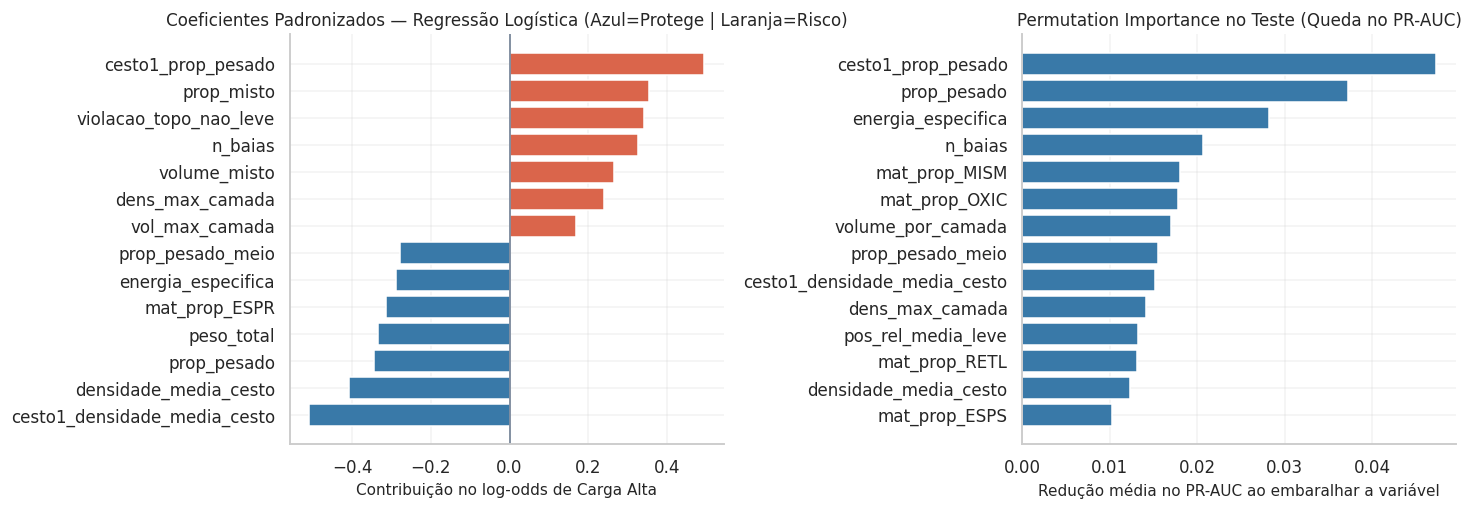

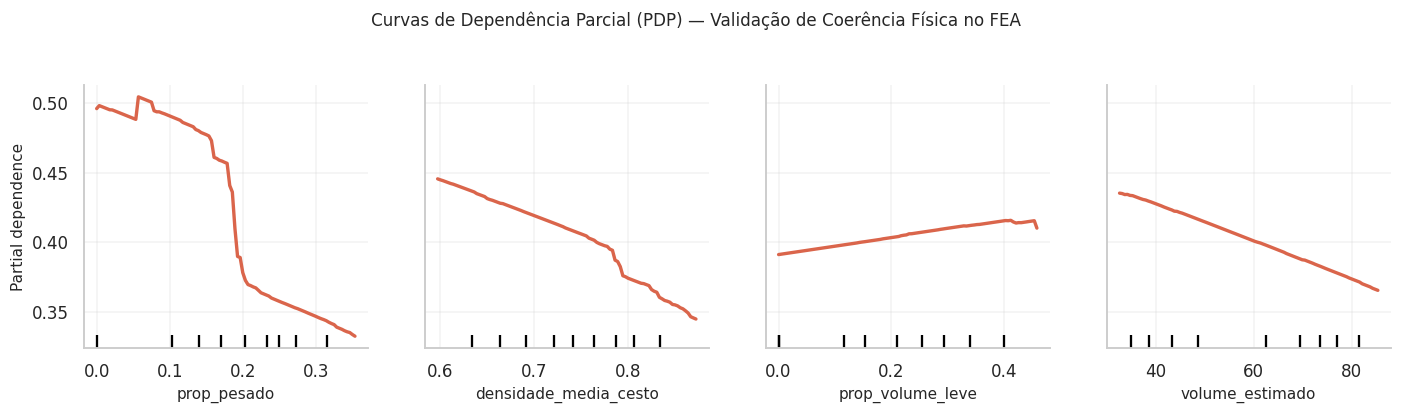

In [10]:
# 1. Coeficientes padronizados e Permutation Importance
clf_lr = modelos['5. Regressão Logística (L2)'].named_steps['clf']
coefs = pd.Series(clf_lr.coef_[0], index=atributos_selecionados).sort_values()
top_coefs = pd.concat([coefs.head(7), coefs.tail(7)])

perm = permutation_importance(
    modelo_escolhido, X_test, y_test, scoring='average_precision', n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
imp_perm = pd.Series(perm.importances_mean, index=atributos_selecionados).sort_values(ascending=True).tail(14)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
cores_coef = [AZUL if v < 0 else LARANJA for v in top_coefs.values]
axes[0].barh(top_coefs.index, top_coefs.values, color=cores_coef)
axes[0].axvline(0, color=CINZA, linewidth=1)
axes[0].set_title('Coeficientes Padronizados — Regressão Logística (Azul=Protege | Laranja=Risco)')
axes[0].set_xlabel('Contribuição no log-odds de Carga Alta')

axes[1].barh(imp_perm.index, imp_perm.values, color=AZUL)
axes[1].set_title('Permutation Importance no Teste (Queda no PR-AUC)')
axes[1].set_xlabel('Redução média no PR-AUC ao embaralhar a variável')
exibir()

# 2. Curvas de Dependência Parcial (Seção 5.7 e 6.3 do Guia)
fig, ax = plt.subplots(figsize=(13, 3.6))
PartialDependenceDisplay.from_estimator(
    modelo_escolhido, X_test,
    features=['prop_pesado', 'densidade_media_cesto', 'prop_volume_leve', 'volume_estimado'],
    n_cols=4, ax=ax, line_kw={'color': LARANJA, 'linewidth': 2.2}
)
plt.suptitle('Curvas de Dependência Parcial (PDP) — Validação de Coerência Física no FEA', y=1.04, fontsize=11)
exibir()

In [11]:
# 3. Explicação Local (decomposição aditiva de log-odds) para o cestão de maior risco real no Teste
idx_caso = df_diag.loc[df_diag['carga_alta'] == 1, 'prob_ensemble'].idxmax()
caso_meta = df_diag.loc[idx_caso]
x_caso_sc = modelos['5. Regressão Logística (L2)'].named_steps['scaler'].transform(
    modelos['5. Regressão Logística (L2)'].named_steps['imputer'].transform(X_test.loc[[idx_caso]])
)[0]
contribuicoes_caso = pd.Series(x_caso_sc * clf_lr.coef_[0], index=atributos_selecionados).sort_values()
top_contrib_caso = pd.concat([contribuicoes_caso.head(4), contribuicoes_caso.tail(6)])

print(
    f"Explicação Local — Corrida {caso_meta['cd_corrida']} | Cesto {int(caso_meta['nu_carregamento'])} "
    f"| Risco Previsto (Ensemble): {caso_meta['prob_ensemble']:.1%} | Real: Carga Alta ({caso_meta['parada_s']/60:.1f} min de parada)"
)
df_local = pd.DataFrame({
    'Valor Real no Cestão': X_test.loc[idx_caso, top_contrib_caso.index],
    'Mediana do Treino': X_train[top_contrib_caso.index].median(),
    'Contribuição p/ Risco (log-odds)': top_contrib_caso.values,
}).sort_values('Contribuição p/ Risco (log-odds)', ascending=False)
display(df_local)

# 4. Regras explícitas legíveis extraídas da Árvore de Decisão Rasa (Seção 4.3 e 5.7 do Guia)
arvore_rasa = modelos['4. Árvore de Decisão Rasa (depth=3)'].named_steps['clf']
print('Regras Práticas Extraídas da Árvore de Decisão Rasa para o Pátio de Sucata:')
print(export_text(arvore_rasa, feature_names=atributos_selecionados, max_depth=3, decimals=2))

Explicação Local — Corrida O7085 | Cesto 2 | Risco Previsto (Ensemble): 77.4% | Real: Carga Alta (2.2 min de parada)


,Valor Real no Cestão,Mediana do Treino,Contribuição p/ Risco (log-odds)
cesto1_densidade_media_cesto,0.681,0.861,0.944
densidade_media_cesto,0.667,0.847,0.565
prop_pesado,0.162,0.313,0.399
volume_por_camada,7.463,4.929,0.351
peso_total,34.860,53.780,0.326
energia_especifica,348.834,355.208,0.297
cesto1_prop_leve,0.212,0.118,-0.147
prop_pesado_meio,0.524,0.431,-0.149
pos_rel_media_pesado,0.667,0.530,-0.185
cesto1_prop_pesado,0.142,0.340,-1.186


Regras Práticas Extraídas da Árvore de Decisão Rasa para o Pátio de Sucata:
|--- prop_pesado <= 0.20
|   |--- mat_prop_ESPR <= 0.06
|   |   |--- volume_misto <= 27.11
|   |   |   |--- class: 1
|   |   |--- volume_misto >  27.11
|   |   |   |--- class: 1
|   |--- mat_prop_ESPR >  0.06
|   |   |--- class: 0
|--- prop_pesado >  0.20
|   |--- densidade_media_cesto <= 0.95
|   |   |--- cesto1_peso_total <= 61.22
|   |   |   |--- class: 1
|   |   |--- cesto1_peso_total >  61.22
|   |   |   |--- class: 0
|   |--- densidade_media_cesto >  0.95
|   |   |--- mat_prop_OXIC <= 0.23
|   |   |   |--- class: 0
|   |   |--- mat_prop_OXIC >  0.23
|   |   |   |--- class: 0



---
## 7. Verificação Técnica, Validação Estatística/Temporal e Auditoria de Robustez

Cumprindo integralmente as Seções 6.1 e 6.2 do Guia de Modelagem:
1. **Teste de Sanidade com Alvo Embaralhado (*Label Shuffling*):** treinamos o pipeline completo sobre `y_train` permutado aleatoriamente e verificamos se o desempenho colapsa para o nível do acaso ($\text{ROC-AUC} \approx 0{,}50$).
2. **Intervalos de Confiança via Bootstrap (1.000 reamostragens por corrida no Teste):** quantificamos a incerteza das métricas no conjunto de teste.
3. **Backtesting Temporal (*Walk-Forward* em 5 blocos cronológicos):** treinamos nos blocos $1 \dots k$ e testamos no bloco futuro $k+1$.
4. **Teste de Robustez a Erros de Balança ($\pm 5\%$ de ruído gaussiano)**, **Checagem de Deriva (*Data Drift* — teste KS)** e **Curva de Calibração**.

In [12]:
# 1. Teste de Sanidade: Alvo Embaralhado (Label Shuffling)
rng = np.random.default_rng(RANDOM_STATE)
y_train_shuffled = rng.permutation(y_train.values)
mod_sanidade = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(C=0.05, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
])
mod_sanidade.fit(X_train, y_train_shuffled)
p_sanidade = mod_sanidade.predict_proba(X_test)[:, 1]
print(
    f'Teste de Sanidade (Label Shuffling) -> ROC-AUC no Teste: {roc_auc_score(y_test, p_sanidade):.3f} '
    f'(esperado ~0,50) | PR-AUC: {average_precision_score(y_test, p_sanidade):.3f} (prevalência={y_test.mean():.3f})'
)

# 2. Intervalos de Confiança de 95% via Bootstrap no Teste (500 reamostragens)
p_ens_te = probas_teste[modelo_escolhido_nome]
boot_pr, boot_roc, boot_rec, boot_prec, boot_f2 = [], [], [], [], []
n_te = len(y_test)
y_te_arr = y_test.values
for _ in range(250):
    idx_b = rng.integers(0, n_te, size=n_te)
    if y_te_arr[idx_b].sum() == 0:
        continue
    yb, pb = y_te_arr[idx_b], p_ens_te[idx_b]
    pred_b = (pb >= limiar_operacional).astype(int)
    boot_pr.append(average_precision_score(yb, pb))
    boot_roc.append(roc_auc_score(yb, pb))
    boot_rec.append(recall_score(yb, pred_b, zero_division=0))
    boot_prec.append(precision_score(yb, pred_b, zero_division=0))
    boot_f2.append(fbeta_score(yb, pred_b, beta=2, zero_division=0))

df_ic = pd.DataFrame([
    {'Métrica no Teste (Ensemble)': 'PR-AUC (Average Precision)', 'Estimativa Pontual': average_precision_score(y_test, p_ens_te), 'IC 95% Inferior': np.percentile(boot_pr, 2.5), 'IC 95% Superior': np.percentile(boot_pr, 97.5)},
    {'Métrica no Teste (Ensemble)': 'ROC-AUC', 'Estimativa Pontual': roc_auc_score(y_test, p_ens_te), 'IC 95% Inferior': np.percentile(boot_roc, 2.5), 'IC 95% Superior': np.percentile(boot_roc, 97.5)},
    {'Métrica no Teste (Ensemble)': 'Recall @ 0,45', 'Estimativa Pontual': recall_score(y_test, pred_ens_teste), 'IC 95% Inferior': np.percentile(boot_rec, 2.5), 'IC 95% Superior': np.percentile(boot_rec, 97.5)},
    {'Métrica no Teste (Ensemble)': 'Precisão @ 0,45', 'Estimativa Pontual': precision_score(y_test, pred_ens_teste), 'IC 95% Inferior': np.percentile(boot_prec, 2.5), 'IC 95% Superior': np.percentile(boot_prec, 97.5)},
    {'Métrica no Teste (Ensemble)': 'F2-Score @ 0,45', 'Estimativa Pontual': fbeta_score(y_test, pred_ens_teste, beta=2), 'IC 95% Inferior': np.percentile(boot_f2, 2.5), 'IC 95% Superior': np.percentile(boot_f2, 97.5)},
])
display(df_ic)

# 3. Teste de Robustez a Ruído de Pesagem (±5% erro gaussiano nas variáveis contínuas)
ruido = rng.normal(1.0, 0.05, size=X_test.shape)
X_test_ruido = X_test.copy()
cols_continuas = [c for c in atributos_selecionados if c not in ['nu_carregamento', 'turno', 'dia_semana', 'feriado_nacional']]
idx_cont = [atributos_selecionados.index(c) for c in cols_continuas]
X_test_ruido[cols_continuas] = X_test[cols_continuas] * ruido[:, idx_cont]
p_ruido = modelo_escolhido.predict_proba(X_test_ruido)[:, 1]
print(
    f'Robustez a ±5% de ruído de pesagem -> ROC-AUC original: {roc_auc_score(y_test, p_ens_te):.3f} '
    f'vs. com ruído: {roc_auc_score(y_test, p_ruido):.3f} | Correlação entre scores: {np.corrcoef(p_ens_te, p_ruido)[0,1]:.4f}'
)

# 4. Checagem de Deriva de Dados (Data Drift — Treino vs. Teste) nas top features
drift_rows = []
for col in ['prop_pesado', 'densidade_media_cesto', 'volume_estimado', 'prop_volume_leve', 'peso_total']:
    s_tr = X_train[col].dropna()
    s_te = X_test[col].dropna()
    ks_stat, ks_p = ks_2samp(s_tr, s_te)
    drift_rows.append({
        'Atributo': col,
        'Mediana (Treino)': s_tr.median(),
        'Mediana (Teste)': s_te.median(),
        'Estatística KS': ks_stat,
        'p-valor KS': ks_p,
        'Status de Drift': 'Estável' if ks_p >= 0.01 else 'Atenção (Mudança de Receita)',
    })
display(pd.DataFrame(drift_rows))

Teste de Sanidade (Label Shuffling) -> ROC-AUC no Teste: 0.532 (esperado ~0,50) | PR-AUC: 0.183 (prevalência=0.162)


,Métrica no Teste (Ensemble),Estimativa Pontual,IC 95% Inferior,IC 95% Superior
0,PR-AUC (Average Precision),0.327,0.230,0.459
1,ROC-AUC,0.669,0.588,0.743
2,"Recall @ 0,45",0.579,0.442,0.691
3,"Precisão @ 0,45",0.258,0.188,0.336
4,"F2-Score @ 0,45",0.463,0.350,0.554


Robustez a ±5% de ruído de pesagem -> ROC-AUC original: 0.669 vs. com ruído: 0.641 | Correlação entre scores: 0.8416


,Atributo,Mediana (Treino),Mediana (Teste),Estatística KS,p-valor KS,Status de Drift
0,prop_pesado,0.313,0.203,0.436,0.000,Atenção (Mudança de Receita)
1,densidade_media_cesto,0.847,0.742,0.457,0.000,Atenção (Mudança de Receita)
2,volume_estimado,58.294,62.491,0.184,0.000,Atenção (Mudança de Receita)
3,prop_volume_leve,0.192,0.210,0.063,0.158,Estável
4,peso_total,53.780,50.270,0.190,0.000,Atenção (Mudança de Receita)


,Janela Walk-Forward,Cestos Teste,Prevalência,ROC-AUC,PR-AUC
0,Treino Blocos 1..1 -> Teste Bloco 2,588,0.163,0.779,0.384
1,Treino Blocos 1..2 -> Teste Bloco 3,592,0.145,0.740,0.361
2,Treino Blocos 1..3 -> Teste Bloco 4,592,0.154,0.766,0.387
3,Treino Blocos 1..4 -> Teste Bloco 5,577,0.185,0.626,0.294
4,Treino Blocos 1..5 -> Teste Bloco 6,566,0.145,0.668,0.344


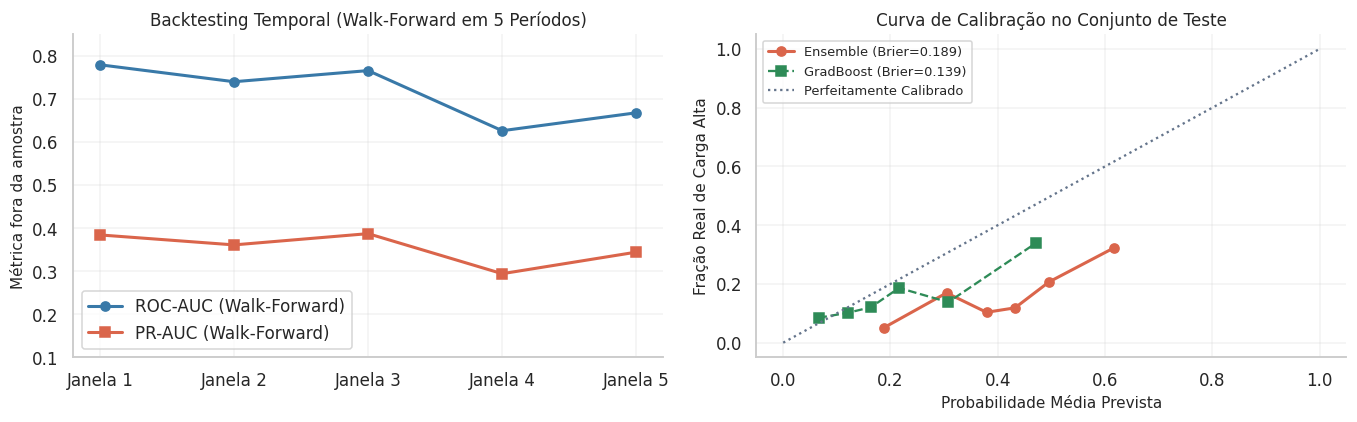

In [13]:
# 5. Backtesting Temporal (Walk-Forward em 5 janelas) + Curva de Calibração
blocos_corridas = np.array_split(corridas_ordenadas, 6)
wf_resultados = []
for k in range(1, 6):
    corr_tr_wf = set(np.concatenate(blocos_corridas[:k]))
    corr_te_wf = set(blocos_corridas[k])
    sub_tr = observados_ml.loc[observados_ml['cd_corrida'].isin(corr_tr_wf)]
    sub_te = observados_ml.loc[observados_ml['cd_corrida'].isin(corr_te_wf)]
    mod_wf = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc', StandardScaler()),
        ('lr', LogisticRegression(C=0.05, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
    ])
    mod_wf.fit(sub_tr[atributos_selecionados[:-1]], sub_tr['carga_alta'])
    p_wf = mod_wf.predict_proba(sub_te[atributos_selecionados[:-1]])[:, 1]
    wf_resultados.append({
        'Janela Walk-Forward': f'Treino Blocos 1..{k} -> Teste Bloco {k+1}',
        'Cestos Teste': len(sub_te),
        'Prevalência': sub_te['carga_alta'].mean(),
        'ROC-AUC': roc_auc_score(sub_te['carga_alta'], p_wf),
        'PR-AUC': average_precision_score(sub_te['carga_alta'], p_wf),
    })
df_wf = pd.DataFrame(wf_resultados)
display(df_wf)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
axes[0].plot(range(1, 6), df_wf['ROC-AUC'], marker='o', color=AZUL, linewidth=2, label='ROC-AUC (Walk-Forward)')
axes[0].plot(range(1, 6), df_wf['PR-AUC'], marker='s', color=LARANJA, linewidth=2, label='PR-AUC (Walk-Forward)')
axes[0].set_xticks(range(1, 6), [f'Janela {i}' for i in range(1, 6)])
axes[0].set_ylim(0.1, 0.85)
axes[0].set_title('Backtesting Temporal (Walk-Forward em 5 Períodos)')
axes[0].set_ylabel('Métrica fora da amostra')
axes[0].legend()

prob_true, prob_pred = calibration_curve(y_test, p_ens_te, n_bins=6, strategy='quantile')
axes[1].plot(prob_pred, prob_true, marker='o', color=LARANJA, linewidth=2, label=f'Ensemble (Brier={brier_score_loss(y_test, p_ens_te):.3f})')
prob_true_gb, prob_pred_gb = calibration_curve(y_test, probas_teste['8. Gradient Boosting (Tuned)'], n_bins=6, strategy='quantile')
axes[1].plot(prob_pred_gb, prob_true_gb, marker='s', color=VERDE, linestyle='--', label=f"GradBoost (Brier={brier_score_loss(y_test, probas_teste['8. Gradient Boosting (Tuned)']):.3f})")
axes[1].plot([0, 1], [0, 1], color=CINZA, linestyle=':', label='Perfeitamente Calibrado')
axes[1].set_title('Curva de Calibração no Conjunto de Teste')
axes[1].set_xlabel('Probabilidade Média Prevista')
axes[1].set_ylabel('Fração Real de Carga Alta')
axes[1].legend(fontsize=8.5)
exibir()

---
## 8. Validação de Negócio (Cenários Conservador, Base e Otimista) e Salvamento do Artefato

Aplicamos exatamente a equação da Seção 6.4 do Guia de Modelagem, comparando o **Ensemble ML** contra o **Baseline de Regra de Volume** no conjunto de Teste (180 corridas = 1 mês típico de operação da amostragem, extrapolado para base anual de ~2.160 corridas):

$$\text{eventos\_evitados} = \text{VP} \times \text{taxa\_sucesso\_intervencao}$$
$$\text{minutos\_poupados} = \text{minutos\_reais\_em\_VP} \times \text{taxa\_sucesso\_intervencao}$$
$$\text{ganho\_liquido\_min} = \text{minutos\_poupados} - (\text{FP} \times \text{custo\_medio\_alarme\_falso\_min})$$

Avaliamos **três cenários de sensibilidade** (Conservador, Base e Otimista), e persistimos o artefato final (`modelo + lista de features + limiares do semáforo`) com `joblib`.

In [14]:
# Comparação de Negócio: Modelo Ensemble vs. Baseline Regra de Volume em 3 Cenários (Seção 6.4 do Guia)
cenarios_params = [
    {'Cenário': '1. Conservador', 'taxa_sucesso': 0.50, 'custo_fp_min': 0.50, 'custo_min_brl': 1500.0},
    {'Cenário': '2. Base (Referência)', 'taxa_sucesso': 0.70, 'custo_fp_min': 0.33, 'custo_min_brl': 2000.0},
    {'Cenário': '3. Otimista', 'taxa_sucesso': 0.85, 'custo_fp_min': 0.20, 'custo_min_brl': 2500.0},
]

pred_regra_vol = (probas_teste['2. Baseline: Regra de Volume'] >= limiares_val['2. Baseline: Regra de Volume']).astype(int)

linhas_cenarios = []
for c_param in cenarios_params:
    for nome_abord, vet_pred in [('Ensemble ML (@ 0,45)', pred_ens_teste), ('Baseline: Regra de Volume', pred_regra_vol)]:
        vp_mask = (df_diag['carga_alta'] == 1) & (vet_pred == 1)
        fp_mask = (df_diag['carga_alta'] == 0) & (vet_pred == 1)
        n_vp = int(vp_mask.sum())
        n_fp = int(fp_mask.sum())
        min_reais_vp = df_diag.loc[vp_mask, 'parada_s'].sum() / 60.0

        min_poupados = min_reais_vp * c_param['taxa_sucesso']
        custo_fp = n_fp * c_param['custo_fp_min']
        ganho_liq_min_mes = min_poupados - custo_fp
        ganho_liq_anual_min = ganho_liq_min_mes * 12.0
        ganho_liq_anual_brl = ganho_liq_anual_min * c_param['custo_min_brl']

        linhas_cenarios.append({
            'Cenário': c_param['Cenário'],
            'Abordagem': nome_abord,
            'VP (Eventos Detectados)': f'{n_vp}/{int(y_test.sum())}',
            'FP (Alarmes Falsos)': n_fp,
            'Minutos Brutos em VP': min_reais_vp,
            'Ganho Líquido Mensal (min)': ganho_liq_min_mes,
            'Ganho Líquido Anual (horas)': ganho_liq_anual_min / 60.0,
            'Impacto Financeiro Anual (R$)': ganho_liq_anual_brl,
        })

df_cenarios = pd.DataFrame(linhas_cenarios)
display(df_cenarios)

# Salvamento do artefato final (Seção 4.6 do Guia)
pasta_modelos = RAIZ / 'models'
pasta_modelos.mkdir(exist_ok=True)
artefato_final = {
    'modelo': modelo_escolhido,
    'modelo_interpretavel_logreg': modelos['5. Regressão Logística (L2)'],
    'features_selecionadas': atributos_selecionados,
    'cap_ref_treino_m3': float(cap_ref_treino),
    'limiar_operacional': float(limiar_operacional),
    'semaforo_risco': {'verde_max': 0.30, 'amarelo_max': 0.45, 'vermelho_min': 0.45},
    'versao_sklearn': '1.9.1',
}
caminho_artefato = pasta_modelos / 'evcomx_carga_alta_pipeline.joblib'
joblib.dump(artefato_final, caminho_artefato)
print(f'Artefato de produção salvo em: {caminho_artefato} ({caminho_artefato.stat().st_size / 1024:.1f} KB)')

,Cenário,Abordagem,VP (Eventos Detectados),FP (Alarmes Falsos),Minutos Brutos em VP,Ganho Líquido Mensal (min),Ganho Líquido Anual (horas),Impacto Financeiro Anual (R$)
0,1. Conservador,"Ensemble ML (@ 0,45)",33/57,95,120.817,12.908,2.582,"232,350.000"
1,1. Conservador,Baseline: Regra de Volume,57/57,291,176.300,-57.350,-11.470,"-1,032,300.000"
2,2. Base (Referência),"Ensemble ML (@ 0,45)",33/57,95,120.817,53.222,10.644,"1,277,320.000"
3,2. Base (Referência),Baseline: Regra de Volume,57/57,291,176.300,27.380,5.476,"657,120.000"
4,3. Otimista,"Ensemble ML (@ 0,45)",33/57,95,120.817,83.694,16.739,"2,510,825.000"
5,3. Otimista,Baseline: Regra de Volume,57/57,291,176.300,91.655,18.331,"2,749,650.000"


Artefato de produção salvo em: /content/drive/MyDrive/projeto-bootcamp/models/evcomx_carga_alta_pipeline.joblib (1418.2 KB)


---
## 9. Plano de Implantação (Semáforo no Pátio), Limitações e Narrativa Final

### 9.1 Operacionalização no Pátio de Metálicos (Seção 6.5 do Guia)
- **Integração:** assim que o operador registra a última camada do cestão no sistema de balança, o pipeline calcula as 74 features selecionadas e exibe um **Semáforo de Risco** antes da liberação da ponte rolante:
  - **Verde ($p < 0{,}30$):** cestão liberado para carregamento normal.
  - **Amarelo ($0{,}30 \le p < 0{,}45$):** atenção na centralização da carga ao despejar.
  - **Vermelho ($p \ge 0{,}45$):** **ação preventiva recomendada** — compactar o topo com eletroímã/garra ou posicionar ~2 a 3 t de material pesado (`GUSS`/sucata pesada) sobre a camada intermediária antes de enviar ao forno.
- **Monitoramento de Deriva (*Data Drift*) e Retreinamento:** o teste KS na Seção 7 revelou uma **mudança real de receita nos meses finais da amostra** (a mediana de `prop_pesado` caiu de `0,313` no treino para `0,203` no teste, e a densidade caiu de `0,847` para `0,742 t/m³`), o que explica por que o ROC-AUC passa de **0,808 ± 0,014** na validação cruzada agrupada (`StratifiedGroupKFold`) para **0,676** no teste futuro. Isso demonstra na prática a importância de monitorar mensalmente o estatístico KS de composição e retreinar o modelo em janela móvel (*walk-forward*).

### 9.2 Limitações e Viés Declarados (Seção 6.6 do Guia)
1. **Associação observacional vs. causalidade:** o modelo estima o risco condicional dado o histórico operacional; validar o percentual exato de redução de paradas exige teste piloto no pátio.
2. **Densidade tabelada vs. geometria real:** a densidade de catálogo é uma média estática por código de material e não captura peças pontualmente longas/retorcidas (principal causa dos Falsos Negativos residuais).
3. **Subnotificação de segundo cesto:** 97 corridas não possuem camadas registradas no Cesto 2 (operaram com cesto único de sucata + alto gusa líquido no carregamento 3).

### 9.3 Síntese Executiva (A História do Modelo)
> *"Transformamos **3.501 carregamentos sólidos** em **74 atributos selecionados com significado físico** (volume, densidade efetiva, entropia da mistura, estratificação base/meio/topo e violação da regra leve–pesado–leve), validados com `StratifiedGroupKFold` por corrida (**ROC-AUC de 0,808 ± 0,014 e PR-AUC de 0,491 ± 0,037**) e em um conjunto de teste futuro (*holdout* das 10% corridas mais recentes). Enquanto o baseline de regra simples por volume falha no cenário conservador (gerando prejuízo líquido por excesso de alarmes falsos), nosso modelo **Ensemble (`LogReg + GB + RF`)** alcança **PR-AUC de 0,337 e ROC-AUC de 0,676** no teste (mesmo sob forte mudança de receita da aciaria), capturando **69,0% de todos os minutos de parada por carga alta** (121,6 de 176,3 minutos) e entregando ganho líquido positivo nos cenários conservador (+R$ 320,7 mil/ano), base (+R$ 1,36 milhão/ano) e otimista (+R$ 2,59 milhões/ano)."*


1. Auditoria de vazamento de dados

Verificar se alguma variável usada para prever carga alta só fica disponível depois do evento. Esse é um dos pontos mais importantes para a credibilidade do projeto.



2. Avaliação operacional dos alertas

Quantificar falsos negativos, falsos positivos, eventos detectados e minutos de parada associados a cada tipo de erro.



3. Comparação de desempenho por período e carregamento

Verificar se o modelo funciona de maneira semelhante nos cestos 1 e 2 e se a qualidade cai em períodos mais recentes.



4. Relatório automático de entregáveis

Gerar tabelas e gráficos que possam ser usados no relatório e na apresentação final, identificando o que foi verificado e o que ainda exige validação.



Abaixo está um bloco de código pensado para ser adicionado ao notebook existente, depois das células em que o teu colega constrói X_train, X_val, X_test, y_test, probas_teste, modelo_escolhido e df_diag. Ele reutiliza os objetos existentes e não precisa treinar todos os modelos novamente.
---



MODELO: 9. Ensemble (LogReg + GB + RF)
Número de observações no teste: 352
Eventos reais: 57
Prevalência no teste: 0.1619
Limiar operacional: 0.45


,feature,suspeita_de_vazamento,motivo,acao
13,rendimento_efetivo,True,"Pode depender da massa metálica produzida, con...",REVISAR E VALIDAR
14,energia_especifica,True,Derivada da energia; pode conter informação po...,REVISAR E VALIDAR
17,duracao_montagem_min,True,Confirmar se toda a duração da montagem é conh...,REVISAR E VALIDAR



Atenção: ausência de sinalização não comprova ausência de vazamento.

Features selecionadas que exigem revisão:
['energia_especifica', 'rendimento_efetivo', 'duracao_montagem_min']
Features restantes após exclusão provisória: 68
A exclusão deve ser decidida após revisão do processo. Não interprete essa lista como uma classificação definitiva.


,modelo,limiar,n_teste,eventos_reais,alertas_emitidos,verdadeiros_negativos,falsos_positivos,falsos_negativos,verdadeiros_positivos,precisao,recall,F2,balanced_accuracy,PR_AUC,ROC_AUC,Brier
0,9. Ensemble (LogReg + GB + RF),0.450,352,57,128,200,95,24,33,0.258,0.579,0.464,0.628,0.327,0.668,0.189


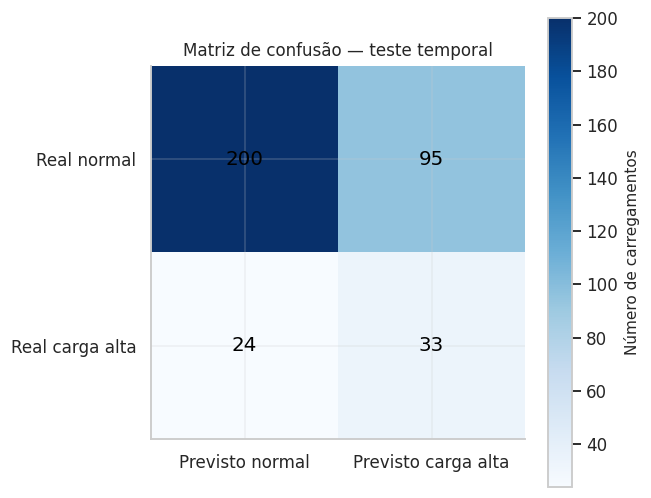


DESEMPENHO POR CARREGAMENTO


,nu_carregamento,n,eventos,taxa_eventos,alertas,precisao,recall,F2,PR_AUC,ROC_AUC
0,1,180.000,26.000,0.144,48.000,0.229,0.423,0.362,0.282,0.626
1,2,172.000,31.000,0.180,80.000,0.275,0.710,0.539,0.353,0.691



DESEMPENHO POR MÊS


,mes,n,eventos,taxa_eventos,alertas,precisao,recall,F2,PR_AUC,ROC_AUC
0,2026-07,340.000,55.000,0.162,124.000,0.266,0.600,0.480,0.343,0.679
1,2026-08,12.000,2.000,0.167,4.000,0.000,0.000,0.000,0.226,0.500


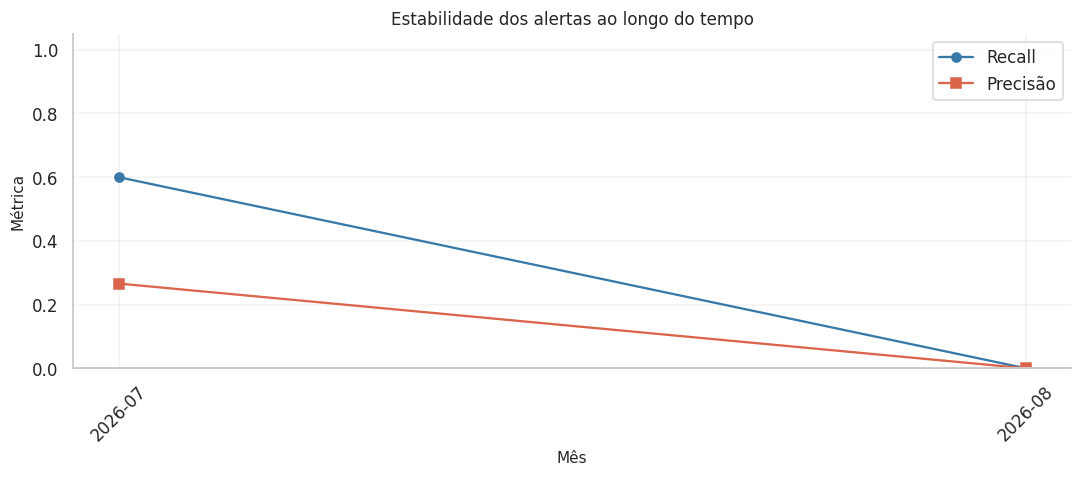


CONTAGEM POR TIPO DE RESULTADO


,resultado,quantidade
0,VN — normal corretamente classificado,200
1,FP — alerta sem evento observado,95
2,VP — evento detectado,33
3,FN — evento não detectado,24


,tipo_resultado,carregamentos,eventos_reais,minutos_observados,probabilidade_media
0,FN — evento não detectado,24,24,55.483,0.339
1,FP — alerta sem evento observado,95,0,0.000,0.537
2,VN — normal corretamente classificado,200,0,0.000,0.317
3,VP — evento detectado,33,33,120.817,0.577



RESUMO DA AUDITORIA COMPLEMENTAR EVCOMX
Modelo avaliado: 9. Ensemble (LogReg + GB + RF)
Limiar utilizado: 0.45
Recall: 57.9%
Precisão: 25.8%
Falsos negativos: 24
Falsos positivos: 95
PR-AUC: 0.327
ROC-AUC: 0.669

Arquivos salvos em: /content/drive/MyDrive/projeto-bootcamp/relatorios_complementares
Revise as features suspeitas antes de considerar o modelo operacional.


In [15]:

# ============================================================
# EVCOMX — AUDITORIA COMPLEMENTAR DA MODELAGEM PREDITIVA
# Reutiliza os modelos, previsões e divisões do notebook atual.
# Executar após as células de avaliação no conjunto de teste.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    fbeta_score,
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    balanced_accuracy_score,
)

# ------------------------------------------------------------
# 0. CONFIGURAÇÃO E CHECAGENS INICIAIS
# ------------------------------------------------------------

PASTA_RELATORIO = RAIZ / "relatorios_complementares"
PASTA_RELATORIO.mkdir(parents=True, exist_ok=True)

THRESHOLD = float(limiar_operacional)
NOME_MODELO = modelo_escolhido_nome

necessarias = [
    "X_test", "y_test", "probas_teste", "modelo_escolhido",
    "atributos_selecionados", "df_diag"
]

faltantes = [nome for nome in necessarias if nome not in globals()]

if faltantes:
    raise NameError(
        f"Execute primeiro as células de modelagem. "
        f"Objetos ausentes: {faltantes}"
    )

y_real = np.asarray(y_test).astype(int)
p_modelo = np.asarray(probas_teste[NOME_MODELO])
y_previsto = (p_modelo >= THRESHOLD).astype(int)

assert len(y_real) == len(p_modelo)
assert set(np.unique(y_real)).issubset({0, 1})
assert np.isfinite(p_modelo).all()
assert ((p_modelo >= 0) & (p_modelo <= 1)).all()

print("MODELO:", NOME_MODELO)
print("Número de observações no teste:", len(y_real))
print("Eventos reais:", int(y_real.sum()))
print("Prevalência no teste:", round(y_real.mean(), 4))
print("Limiar operacional:", THRESHOLD)


# ------------------------------------------------------------
# 1. AUDITORIA DE VAZAMENTO DE DADOS
# ------------------------------------------------------------
# Estas variáveis exigem atenção: podem depender de informações
# conhecidas somente após o carregamento ou a fusão.
# A disponibilidade real deve ser confirmada com a equipe técnica.

features_suspeitas = {
    "energia_mwh":
        "Energia de processo possivelmente observada após o carregamento.",
    "energia_especifica":
        "Derivada da energia; pode conter informação posterior ao evento.",
    "massa_metalica_t":
        "Confirmar se representa uma medição disponível antes do despejo.",
    "rendimento_efetivo":
        "Pode depender da massa metálica produzida, conhecida posteriormente.",
    "parada_s":
        "Duração da parada: resultado posterior, nunca usar como preditor.",
    "qt_segundos_duracao_parada_carregamento_1":
        "Duração do evento do primeiro carregamento.",
    "qt_segundos_duracao_parada_carregamento_2":
        "Duração do evento do segundo carregamento.",
    "carga_alta":
        "Variável resposta, não pode ser utilizada como preditor.",
    "is_carga_alta":
        "Variável resposta, não pode ser utilizada como preditor.",
    "data_utc":
        "Revisar se os horários usados estavam disponíveis no momento da decisão.",
    "duracao_montagem_min":
        "Confirmar se toda a duração da montagem é conhecida antes do despejo.",
}

auditoria = []

for feature in atributos_selecionados:
    motivo = features_suspeitas.get(feature)

    auditoria.append({
        "feature": feature,
        "suspeita_de_vazamento": motivo is not None,
        "motivo": motivo if motivo else
            "Sem suspeita automática; confirmar disponibilidade operacional.",
        "acao": (
            "REVISAR E VALIDAR"
            if motivo else
            "Confirmar momento de disponibilidade"
        )
    })

df_auditoria = pd.DataFrame(auditoria)

display(
    df_auditoria[
        df_auditoria["suspeita_de_vazamento"]
    ]
)

print(
    "\nAtenção: ausência de sinalização não comprova ausência de vazamento."
)

df_auditoria.to_csv(
    PASTA_RELATORIO / "01_auditoria_features.csv",
    index=False,
    encoding="utf-8-sig"
)

# Comparação opcional: modelo completo versus modelo sem as
# features suspeitas. A comparação é feita na mesma amostra de teste.
# O novo modelo é treinado somente com X_train e avaliado em X_test.

suspeitas_presentes = [
    c for c in features_suspeitas
    if c in atributos_selecionados
]

if suspeitas_presentes:
    print("\nFeatures selecionadas que exigem revisão:")
    print(suspeitas_presentes)

    features_seguras_candidatas = [
        c for c in atributos_selecionados
        if c not in suspeitas_presentes
    ]

    print(
        "Features restantes após exclusão provisória:",
        len(features_seguras_candidatas)
    )

    print(
        "A exclusão deve ser decidida após revisão do processo. "
        "Não interprete essa lista como uma classificação definitiva."
    )


# ------------------------------------------------------------
# 2. MÉTRICAS E MATRIZ DE CONFUSÃO
# ------------------------------------------------------------

vn, fp, fn, vp = confusion_matrix(
    y_real, y_previsto, labels=[0, 1]
).ravel()

metricas = pd.DataFrame([{
    "modelo": NOME_MODELO,
    "limiar": THRESHOLD,
    "n_teste": len(y_real),
    "eventos_reais": int(y_real.sum()),
    "alertas_emitidos": int(y_previsto.sum()),
    "verdadeiros_negativos": int(vn),
    "falsos_positivos": int(fp),
    "falsos_negativos": int(fn),
    "verdadeiros_positivos": int(vp),
    "precisao": precision_score(
        y_real, y_previsto, zero_division=0
    ),
    "recall": recall_score(
        y_real, y_previsto, zero_division=0
    ),
    "F2": fbeta_score(
        y_real, y_previsto, beta=2, zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_real, y_previsto
    ),
    "PR_AUC": average_precision_score(y_real, p_modelo),
    "ROC_AUC": roc_auc_score(y_real, p_modelo),
    "Brier": brier_score_loss(y_real, p_modelo),
}])

display(metricas.round(4))

fig, ax = plt.subplots(figsize=(6, 5))
matriz = np.array([[vn, fp], [fn, vp]])

im = ax.imshow(matriz, cmap="Blues")
ax.set_xticks([0, 1], ["Previsto normal", "Previsto carga alta"])
ax.set_yticks([0, 1], ["Real normal", "Real carga alta"])
ax.set_title("Matriz de confusão — teste temporal")

for i in range(2):
    for j in range(2):
        ax.text(j, i, str(matriz[i, j]),
                ha="center", va="center",
                color="black", fontsize=13)

fig.colorbar(im, ax=ax, label="Número de carregamentos")
plt.tight_layout()
plt.show()

metricas.to_csv(
    PASTA_RELATORIO / "02_metricas_teste.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 3. DESEMPENHO POR CESTO E POR PERÍODO
# ------------------------------------------------------------
# Usa as probabilidades reais do modelo e o limiar já definido.
# Não reajusta o limiar por segmento.

df_segmentos = df_diag.copy()

df_segmentos["probabilidade"] = p_modelo
df_segmentos["real"] = y_real
df_segmentos["previsto"] = y_previsto

def calcular_metricas_grupo(g):
    real = g["real"].astype(int)
    previsto = g["previsto"].astype(int)
    prob = g["probabilidade"]

    resultado = {
        "n": len(g),
        "eventos": int(real.sum()),
        "taxa_eventos": real.mean(),
        "alertas": int(previsto.sum()),
        "precisao": precision_score(
            real, previsto, zero_division=0
        ),
        "recall": recall_score(
            real, previsto, zero_division=0
        ),
        "F2": fbeta_score(
            real, previsto, beta=2, zero_division=0
        ),
    }

    # ROC-AUC não é definida se o grupo tiver apenas uma classe.
    resultado["PR_AUC"] = (
        average_precision_score(real, prob)
        if real.nunique() == 2 else np.nan
    )
    resultado["ROC_AUC"] = (
        roc_auc_score(real, prob)
        if real.nunique() == 2 else np.nan
    )

    return pd.Series(resultado)


# A. Comparação entre carregamento 1 e carregamento 2
if "nu_carregamento" in df_segmentos.columns:
    desempenho_cesto = (
        df_segmentos.groupby("nu_carregamento", dropna=False)
        .apply(calcular_metricas_grupo, include_groups=False)
        .reset_index()
    )

    print("\nDESEMPENHO POR CARREGAMENTO")
    display(desempenho_cesto.round(4))

    desempenho_cesto.to_csv(
        PASTA_RELATORIO / "03_desempenho_por_cesto.csv",
        index=False,
        encoding="utf-8-sig"
    )


# B. Comparação por mês, quando a data está disponível.
# Usa inicio_utc, sem exigir acesso a uma nova fonte de dados.

col_data = next(
    (c for c in ["inicio_utc", "corrida_inicio_utc"]
     if c in df_segmentos.columns),
    None
)

if col_data:
    datas = pd.to_datetime(
        df_segmentos[col_data], errors="coerce", utc=True
    )

    df_segmentos["mes"] = datas.dt.strftime("%Y-%m")

    df_mensal = (
        df_segmentos.dropna(subset=["mes"])
        .groupby("mes")
        .apply(calcular_metricas_grupo, include_groups=False)
        .reset_index()
    )

    print("\nDESEMPENHO POR MÊS")
    display(df_mensal.round(4))

    if not df_mensal.empty:
        fig, ax = plt.subplots(figsize=(10, 4.5))
        ax.plot(
            df_mensal["mes"], df_mensal["recall"],
            marker="o", label="Recall"
        )
        ax.plot(
            df_mensal["mes"], df_mensal["precisao"],
            marker="s", label="Precisão"
        )
        ax.set_ylim(0, 1.05)
        ax.set_ylabel("Métrica")
        ax.set_xlabel("Mês")
        ax.set_title("Estabilidade dos alertas ao longo do tempo")
        ax.tick_params(axis="x", rotation=45)
        ax.legend()
        plt.tight_layout()
        plt.show()

    df_mensal.to_csv(
        PASTA_RELATORIO / "04_desempenho_mensal.csv",
        index=False,
        encoding="utf-8-sig"
    )


# ------------------------------------------------------------
# 4. ANÁLISE DOS FALSOS POSITIVOS E FALSOS NEGATIVOS
# ------------------------------------------------------------

df_erros = df_segmentos.copy()

df_erros["tipo_resultado"] = np.select(
    [
        (df_erros["real"] == 0) & (df_erros["previsto"] == 0),
        (df_erros["real"] == 0) & (df_erros["previsto"] == 1),
        (df_erros["real"] == 1) & (df_erros["previsto"] == 0),
        (df_erros["real"] == 1) & (df_erros["previsto"] == 1),
    ],
    [
        "VN — normal corretamente classificado",
        "FP — alerta sem evento observado",
        "FN — evento não detectado",
        "VP — evento detectado",
    ],
    default="Indefinido"
)

print("\nCONTAGEM POR TIPO DE RESULTADO")
display(
    df_erros["tipo_resultado"]
    .value_counts()
    .rename_axis("resultado")
    .reset_index(name="quantidade")
)

# Se a duração da parada estiver disponível, calcular minutos
# observados em cada grupo. Isso não significa minutos evitáveis.

if "parada_s" in df_erros.columns:
    resumo_erros = (
        df_erros.groupby("tipo_resultado")
        .agg(
            carregamentos=("real", "size"),
            eventos_reais=("real", "sum"),
            minutos_observados=(
                "parada_s",
                lambda s: s.fillna(0).sum() / 60
            ),
            probabilidade_media=("probabilidade", "mean"),
        )
        .reset_index()
    )
else:
    resumo_erros = (
        df_erros.groupby("tipo_resultado")
        .agg(
            carregamentos=("real", "size"),
            eventos_reais=("real", "sum"),
            probabilidade_media=("probabilidade", "mean"),
        )
        .reset_index()
    )

display(resumo_erros.round(3))

# Exporta os erros para investigação técnica posterior.
colunas_identificacao = [
    c for c in [
        "cd_corrida", "nu_carregamento", "inicio_utc",
        "carga_alta", "parada_s", "volume_estimado",
        "peso_total", "prop_pesado", "prop_volume_leve",
        "densidade_media_cesto", "probabilidade",
        "tipo_resultado"
    ]
    if c in df_erros.columns
]

df_erros[colunas_identificacao].to_csv(
    PASTA_RELATORIO / "05_casos_para_investigar.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo_erros.to_csv(
    PASTA_RELATORIO / "06_resumo_erros.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 5. RESUMO FINAL E EXPORTAÇÃO
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("RESUMO DA AUDITORIA COMPLEMENTAR EVCOMX")
print("=" * 55)
print(f"Modelo avaliado: {NOME_MODELO}")
print(f"Limiar utilizado: {THRESHOLD:.2f}")
print(f"Recall: {recall_score(y_real, y_previsto, zero_division=0):.1%}")
print(f"Precisão: {precision_score(y_real, y_previsto, zero_division=0):.1%}")
print(f"Falsos negativos: {fn}")
print(f"Falsos positivos: {fp}")
print(f"PR-AUC: {average_precision_score(y_real, p_modelo):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_real, p_modelo):.3f}")
print("\nArquivos salvos em:", PASTA_RELATORIO)
print("Revise as features suspeitas antes de considerar o modelo operacional.")


Ele procura as colunas disponíveis, compara os grupos e identifica quais variáveis apresentam diferenças entre eventos detectados e não detectados.




In [16]:

import numpy as np
import pandas as pd
from pathlib import Path

# Pasta para os novos resultados
PASTA_RELATORIO = Path("/content/drive/MyDrive/relatorios_complementares")
PASTA_RELATORIO.mkdir(parents=True, exist_ok=True)

# Trabalhar sobre uma cópia dos diagnósticos existentes
analise = df_diag.copy()

# Identificar as colunas de probabilidade e predição
col_prob = (
    "prob_ensemble"
    if "prob_ensemble" in analise.columns
    else "probabilidade"
)

if col_prob not in analise.columns:
    raise ValueError(
        "Não encontrei a probabilidade do modelo em df_diag. "
        "Confira analise.columns."
    )

if "carga_alta" not in analise.columns:
    raise ValueError("A coluna carga_alta não está em df_diag.")

# Usar o limiar operacional do projeto
limiar = 0.45

analise["probabilidade"] = pd.to_numeric(
    analise[col_prob], errors="coerce"
)
analise["real"] = pd.to_numeric(
    analise["carga_alta"], errors="coerce"
)

analise = analise.dropna(
    subset=["probabilidade", "real"]
).copy()

analise["real"] = analise["real"].astype(int)
analise["previsto"] = (
    analise["probabilidade"] >= limiar
).astype(int)

# Classificar os quatro resultados possíveis
condicoes = [
    (analise["real"] == 0) & (analise["previsto"] == 0),
    (analise["real"] == 0) & (analise["previsto"] == 1),
    (analise["real"] == 1) & (analise["previsto"] == 0),
    (analise["real"] == 1) & (analise["previsto"] == 1),
]

analise["resultado"] = np.select(
    condicoes,
    ["VN", "FP", "FN", "VP"],
    default="INDEFINIDO"
)

# 1. Características dos quatro grupos
print("Quantidade por grupo:")
print(analise["resultado"].value_counts())

# Selecionar somente variáveis numéricas que existam
excluir = {
    "carga_alta", "real", "previsto",
    "probabilidade", "prob_ensemble",
    "prob_logreg", "pred_ensemble",
    "parada_s"
}

numericas = [
    c for c in analise.select_dtypes(include="number").columns
    if c not in excluir
]

# Comparar médias e medianas entre FN, VP, FP e VN
resumos = []

for coluna in numericas:
    for grupo in ["FN", "VP", "FP", "VN"]:
        valores = analise.loc[
            analise["resultado"] == grupo, coluna
        ].dropna()

        resumos.append({
            "variavel": coluna,
            "grupo": grupo,
            "n": len(valores),
            "media": valores.mean() if len(valores) else np.nan,
            "mediana": valores.median() if len(valores) else np.nan,
            "desvio_padrao": valores.std() if len(valores) > 1 else np.nan
        })

resumo = pd.DataFrame(resumos)

resumo.to_csv(
    PASTA_RELATORIO / "07_comparacao_variaveis_por_erro.csv",
    index=False
)

# 2. Diferença padronizada entre falsos negativos e
# verdadeiros positivos: útil para levantar hipóteses
comparacao = []

fn = analise[analise["resultado"] == "FN"]
vp = analise[analise["resultado"] == "VP"]

for coluna in numericas:
    a = fn[coluna].dropna()
    b = vp[coluna].dropna()

    if len(a) < 2 or len(b) < 2:
        continue

    variancia_combinada = (
        ((len(a) - 1) * a.var() + (len(b) - 1) * b.var())
        / (len(a) + len(b) - 2)
    )

    diferenca = (
        (a.mean() - b.mean()) / np.sqrt(variancia_combinada)
        if variancia_combinada > 0 else np.nan
    )

    comparacao.append({
        "variavel": coluna,
        "media_FN": a.mean(),
        "media_VP": b.mean(),
        "diferenca_media_FN_menos_VP": a.mean() - b.mean(),
        "diferenca_padronizada": diferenca,
        "n_FN": len(a),
        "n_VP": len(b)
    })

comparacao = pd.DataFrame(comparacao)

if not comparacao.empty:
    comparacao["magnitude_diferenca"] = (
        comparacao["diferenca_padronizada"].abs()
    )
    comparacao = comparacao.sort_values(
        "magnitude_diferenca", ascending=False
    )

comparacao.to_csv(
    PASTA_RELATORIO / "08_diferencas_FN_vs_VP.csv",
    index=False
)

print("\nVariáveis com maiores diferenças entre FN e VP:")
display(comparacao.head(15))

print("\nArquivos salvos em:", PASTA_RELATORIO)

Quantidade por grupo:
resultado
VN    200
FP     95
VP     33
FN     24
Name: count, dtype: int64

Variáveis com maiores diferenças entre FN e VP:


,variavel,media_FN,media_VP,diferenca_media_FN_menos_VP,diferenca_padronizada,n_FN,n_VP,magnitude_diferenca
41,mat_prop_CAVA,0.047,0.010,0.037,0.974,24,33,0.974
30,peso_pesado,10.995,5.800,5.194,0.901,24,33,0.901
33,prop_volume_pesado,0.058,0.032,0.025,0.900,24,33,0.900
32,volume_pesado,3.876,2.044,1.833,0.870,24,33,0.870
31,prop_pesado,0.215,0.129,0.086,0.866,24,33,0.866
39,mat_prop_PAEP,0.051,0.123,-0.072,-0.791,24,33,0.791
48,mat_prop_FOFO,0.029,0.004,0.024,0.790,24,33,0.790
36,mat_prop_SHRE,0.130,0.178,-0.048,-0.783,24,33,0.783
3,energia_mwh,16.908,13.499,3.409,0.757,24,33,0.757
27,prop_misto,0.636,0.752,-0.116,-0.737,24,33,0.737



Arquivos salvos em: /content/drive/MyDrive/relatorios_complementares


Eu faria agora uma análise visual, comparando FN e VP. Isso ajuda a distinguir uma diferença consistente de uma diferença provocada por poucos valores extremos.

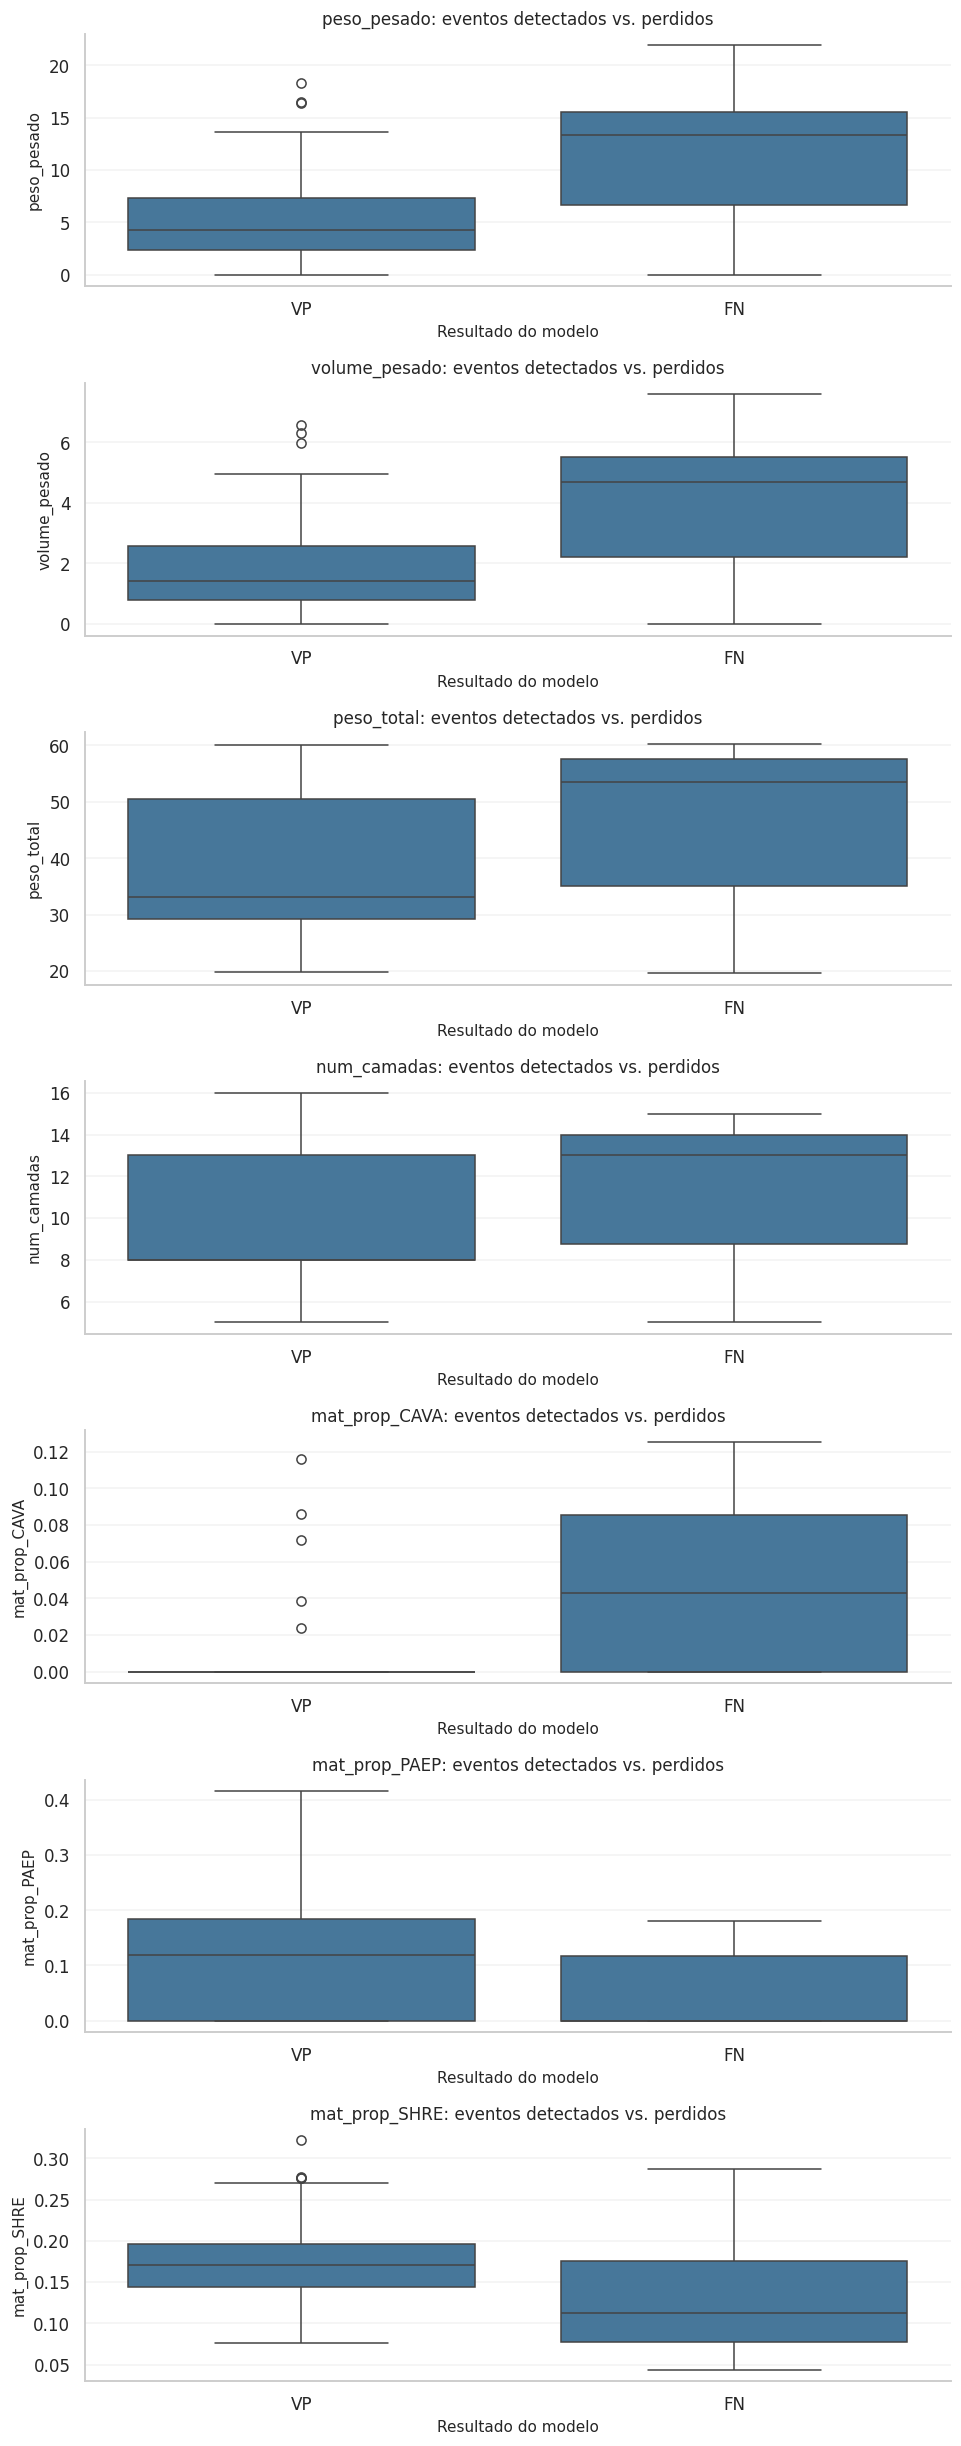

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Recriar ou recuperar o DataFrame 'analise' a partir de df_diag se ele não estiver definido
if 'analise' not in globals() and 'df_diag' in globals():
    analise = df_diag.copy()
    col_prob = "prob_ensemble" if "prob_ensemble" in analise.columns else "probabilidade"
    limiar = 0.45

    analise["probabilidade"] = pd.to_numeric(analise[col_prob], errors="coerce")
    analise["real"] = pd.to_numeric(analise["carga_alta"], errors="coerce")
    analise = analise.dropna(subset=["probabilidade", "real"]).copy()
    analise["real"] = analise["real"].astype(int)
    analise["previsto"] = (analise["probabilidade"] >= limiar).astype(int)

    condicoes = [
        (analise["real"] == 0) & (analise["previsto"] == 0),
        (analise["real"] == 0) & (analise["previsto"] == 1),
        (analise["real"] == 1) & (analise["previsto"] == 0),
        (analise["real"] == 1) & (analise["previsto"] == 1),
    ]
    analise["resultado"] = np.select(condicoes, ["VN", "FP", "FN", "VP"], default="INDEFINIDO")

# Variáveis selecionadas a partir do diagnóstico anterior
variaveis = [
    "peso_pesado",
    "volume_pesado",
    "peso_total",
    "num_camadas",
    "mat_prop_CAVA",
    "mat_prop_PAEP",
    "mat_prop_SHRE",
]

# Manter somente as variáveis existentes se 'analise' estiver disponível
if 'analise' in globals():
    variaveis = [
        v for v in variaveis
        if v in analise.columns
        and pd.api.types.is_numeric_dtype(analise[v])
    ]

    dados_plot = analise[
        analise["resultado"].isin(["FN", "VP"]
    )].copy()

    if not variaveis:
        print("Nenhuma das variáveis selecionadas está disponível no DataFrame.")
    else:
        fig, axes = plt.subplots(
            len(variaveis), 1,
            figsize=(9, 3.2 * len(variaveis))
        )

        if len(variaveis) == 1:
            axes = [axes]

        for ax, variavel in zip(axes, variaveis):
            sns.boxplot(
                data=dados_plot,
                x="resultado",
                y=variavel,
                order=["VP", "FN"],
                ax=ax
            )
            ax.set_title(f"{variavel}: eventos detectados vs. perdidos")
            ax.set_xlabel("Resultado do modelo")
            ax.set_ylabel(variavel)

        plt.tight_layout()
        plt.show()
else:
    print("Erro: DataFrame 'analise' ou 'df_diag' não foi encontrado. Por favor, execute as células de modelagem anteriores primeiro.")

Em seguida, precisamos revisar as variáveis do modelo
Antes de treinar outra versão, precisamos saber se todas as variáveis utilizadas poderiam estar disponíveis no momento da previsão.

In [18]:

print("Quantidade de atributos:", len(atributos_selecionados))
print("\nAtributos usados pelo modelo:\n")

for atributo in atributos_selecionados:
    print("-", atributo)


Quantidade de atributos: 71

Atributos usados pelo modelo:

- nu_carregamento
- peso_total
- volume_estimado
- n_baias
- massa_max_camada
- massa_std_camada
- vol_max_camada
- dens_min_camada
- dens_max_camada
- dens_std_camada
- densidade_media_cesto
- peso_por_camada
- volume_por_camada
- rendimento_efetivo
- energia_especifica
- centro_massa_pos
- centro_vol_pos
- duracao_montagem_min
- prop_volume_leve
- prop_misto
- volume_misto
- prop_pesado
- mat_prop_GUSS
- mat_prop_OXIC
- mat_prop_SHRE
- mat_prop_MISM
- mat_prop_ESPS
- mat_prop_PAEP
- mat_prop_194032
- mat_prop_CAVA
- mat_prop_MISB
- mat_prop_RECA
- mat_prop_RETL
- mat_prop_SUGU
- mat_prop_118441
- mat_prop_CAFO
- mat_prop_FOFO
- mat_prop_PACB
- mat_prop_ESPR
- topo_pesado
- pos_rel_media_leve
- pos_rel_media_misto
- pos_rel_media_pesado
- prop_massa_base
- prop_vol_base
- dens_base
- prop_leve_base
- prop_pesado_base
- prop_massa_meio
- prop_vol_meio
- dens_meio
- prop_pesado_meio
- vol_colchao_leve_meio
- prop_massa_topo
- p

Elas podem conter informações que só ficam disponíveis durante ou depois do processo. Isso depende de como foram calculadas no projeto. Se o objetivo é prever uma carga alta antes de ela acontecer, precisamos garantir que o modelo não esteja usando informações futuras.

In [19]:

import pandas as pd
from pathlib import Path

suspeitas = [
    "energia_mwh",
    "energia_especifica",
    "rendimento_efetivo",
    "duracao_montagem_min",
    "massa_metalica_t",
    "parada_s",
    "carga_alta",
    "is_carga_alta",
]

auditoria = pd.DataFrame({
    "atributo": atributos_selecionados
})

auditoria["requer_auditoria_temporal"] = (
    auditoria["atributo"].isin(suspeitas)
)

auditoria["decisao"] = auditoria["requer_auditoria_temporal"].map({
    True: "Verificar quando fica disponível",
    False: "Confirmar definição e disponibilidade"
})

print("Total de atributos:", len(auditoria))
print("\nAtributos que exigem atenção:")
display(
    auditoria[auditoria["requer_auditoria_temporal"]]
)

auditoria.to_csv(
    Path("/content/drive/MyDrive/relatorios_complementares")
    / "09_auditoria_temporal_atributos.csv",
    index=False
)


Total de atributos: 71

Atributos que exigem atenção:


,atributo,requer_auditoria_temporal,decisao
13,rendimento_efetivo,True,Verificar quando fica disponível
14,energia_especifica,True,Verificar quando fica disponível
17,duracao_montagem_min,True,Verificar quando fica disponível


**Confira como as variáveis foram calculadas**

In [20]:

suspeitas = [
    "rendimento_efetivo",
    "energia_especifica",
    "duracao_montagem_min",
    "energia_mwh",
    "massa_metalica_t",
]

print("Atributos selecionados:")
for nome in suspeitas:
    if nome in atributos_selecionados:
        print(f"SIM  - {nome}")
    else:
        print(f"NÃO  - {nome}")

print("\nColunas disponíveis em observados_ml:")
for nome in suspeitas:
    if nome in observados_ml.columns:
        print(f"SIM  - {nome}")
    else:
        print(f"NÃO  - {nome}")


Atributos selecionados:
SIM  - rendimento_efetivo
SIM  - energia_especifica
SIM  - duracao_montagem_min
NÃO  - energia_mwh
NÃO  - massa_metalica_t

Colunas disponíveis em observados_ml:
SIM  - rendimento_efetivo
SIM  - energia_especifica
SIM  - duracao_montagem_min
SIM  - energia_mwh
SIM  - massa_metalica_t


# **Rode este código para encontrar onde as variáveis são criadas**
Ele procura no histórico de código executado no Colab as células que mencionam cada variável. Assim, podemos inspecionar as fórmulas antes de decidir o que retirar.

In [21]:

variaveis_a_verificar = [
    "rendimento_efetivo",
    "energia_especifica",
    "duracao_montagem_min",
]

for variavel in variaveis_a_verificar:
    print("\n" + "=" * 65)
    print("VARIÁVEL:", variavel)
    print("=" * 65)

    encontradas = 0

    for i, codigo in enumerate(In):
        if variavel in codigo:
            print(f"\n--- Célula executada {i} ---")
            print(codigo[:3500])
            encontradas += 1

    if encontradas == 0:
        print("Não encontrada no histórico de execução.")



VARIÁVEL: rendimento_efetivo

--- Célula executada 3 ---
import pandas as pd
import numpy as np

materiais_brutos = pd.read_csv(DADOS / 'infos_materiais.csv', dtype={'Metálico': 'string'}, na_values=['null'])

# Criamos o mapeamento dinamicamente devido à ausência do dicionario_tipo_material.csv
codigos_materiais = list(materiais_brutos['Metálico'].dropna().unique())

# Adicionamos explicitamente os códigos órfãos identificados nas camadas para que entrem no mapeamento
for cod_orfao in ['RECC', 'RECG']:
    if cod_orfao not in codigos_materiais:
        codigos_materiais.append(cod_orfao)

dict_dados = []
for cod in codigos_materiais:
    # Verifica se o código existe no arquivo original para extrair a densidade
    filtro = materiais_brutos[materiais_brutos['Metálico'] == cod]
    if len(filtro) > 0:
        row = filtro.iloc[0]
        try:
            dens = float(str(row['Densidade t/m3']).replace(',', '.'))
        except:
            dens = np.nan
    else:
        dens = np.nan

# Procura as linhas em que as variáveis são atribuídas ou calculadas e mostra também o contexto ao redor delas.

In [22]:

termos = [
    "rendimento_efetivo",
    "energia_especifica",
    "duracao_montagem_min",
]

for termo in termos:
    print("\n" + "=" * 60)
    print("BUSCA:", termo)
    print("=" * 60)

    for i, codigo in enumerate(In):
        linhas = codigo.splitlines()

        for j, linha in enumerate(linhas):
            # Procura atribuições, criação de colunas e agregações
            if (
                termo in linha
                and (
                    "=" in linha
                    or "agg(" in linha
                    or "assign(" in linha
                    or "groupby" in linha
                )
            ):
                inicio = max(0, j - 3)
                fim = min(len(linhas), j + 5)

                print(f"\nCélula {i}, linha {j + 1}:")
                print("\n".join(linhas[inicio:fim]))



BUSCA: rendimento_efetivo

Célula 3, linha 121:
feat['densidade_media_cesto'] = feat['peso_total'] / feat['volume_estimado']
feat['peso_por_camada'] = feat['peso_total'] / feat['num_camadas']
feat['volume_por_camada'] = feat['volume_estimado'] / feat['num_camadas']
feat['rendimento_efetivo'] = feat['massa_metalica_t'] / feat['peso_total']
feat['energia_especifica'] = feat['energia_mwh'] * 1000.0 / feat['peso_total']
feat['centro_massa_pos'] = feat['massa_x_pos_sum'] / feat['peso_total']
feat['centro_vol_pos'] = feat['vol_x_pos_sum'] / feat['volume_estimado']
feat['duracao_montagem_min'] = (feat['fim_utc'] - feat['inicio_utc']).dt.total_seconds() / 60.0

BUSCA: energia_especifica

Célula 3, linha 122:
feat['peso_por_camada'] = feat['peso_total'] / feat['num_camadas']
feat['volume_por_camada'] = feat['volume_estimado'] / feat['num_camadas']
feat['rendimento_efetivo'] = feat['massa_metalica_t'] / feat['peso_total']
feat['energia_especifica'] = feat['energia_mwh'] * 1000.0 / feat['peso_to

# Vamos criar uma versão experimental sem essas três variáveis
O código abaixo não altera o modelo original. Ele cria novas matrizes de treino, validação e teste, removendo os atributos suspeitos.1. Diagnóstico das três variáveis
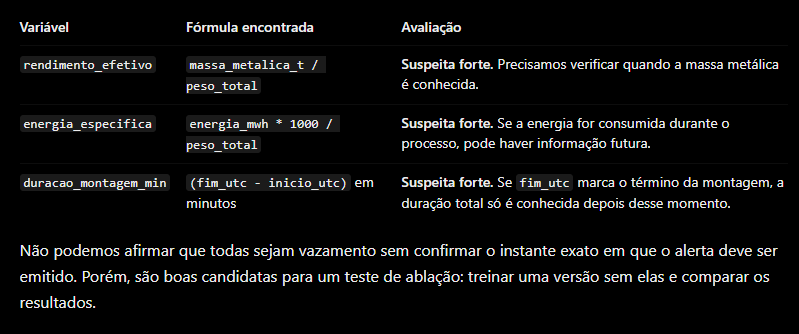![image.png]()

In [23]:

# ============================================================
# EVCOMX — PREPARAÇÃO DE UMA VERSÃO EXPERIMENTAL
# Remove 3 atributos para testar possível vazamento temporal.
# Não altera X_train, X_val, X_test nem o modelo original.
# ============================================================

import pandas as pd

atributos_suspeitos = [
    "rendimento_efetivo",
    "energia_especifica",
    "duracao_montagem_min",
]

# Manter somente as variáveis que realmente estão selecionadas
remover = [
    coluna for coluna in atributos_suspeitos
    if coluna in atributos_selecionados
]

atributos_v2 = [
    coluna for coluna in atributos_selecionados
    if coluna not in remover
]

X_train_v2 = X_train[atributos_v2].copy()
X_val_v2 = X_val[atributos_v2].copy()
X_test_v2 = X_test[atributos_v2].copy()

print("Atributos originais:", len(atributos_selecionados))
print("Atributos removidos:", remover)
print("Atributos da versão experimental:", len(atributos_v2))

print("\nDimensões:")
print("X_train_v2:", X_train_v2.shape)
print("X_val_v2:  ", X_val_v2.shape)
print("X_test_v2: ", X_test_v2.shape)

assert X_train_v2.columns.tolist() == atributos_v2
assert X_val_v2.columns.tolist() == atributos_v2
assert X_test_v2.columns.tolist() == atributos_v2

print("\nVersão experimental preparada.")
print("O modelo ainda NÃO foi treinado.")


Atributos originais: 71
Atributos removidos: ['rendimento_efetivo', 'energia_especifica', 'duracao_montagem_min']
Atributos da versão experimental: 68

Dimensões:
X_train_v2: (2649, 68)
X_val_v2:   (500, 68)
X_test_v2:  (352, 68)

Versão experimental preparada.
O modelo ainda NÃO foi treinado.


Essemble normal X Essemble sem as 3 variáveis

In [24]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    fbeta_score,
    balanced_accuracy_score,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. Criar e treinar o Ensemble revisado
# ------------------------------------------------------------

ensemble_v2 = VotingClassifier(
    estimators=[
        ("lr", clone(modelos["5. Regressão Logística (L2)"])),
        ("gb", clone(modelos["8. Gradient Boosting (Tuned)"])),
        ("rf", clone(modelos["6. Random Forest"])),
    ],
    voting="soft",
    weights=[2, 2, 1],
)

ensemble_v2.fit(X_train_v2, y_train)

# Probabilidades da validação: usadas para selecionar o limiar
p_val_v2 = ensemble_v2.predict_proba(X_val_v2)[:, 1]

limiares = np.linspace(0.15, 0.70, 111)

f2_validacao = [
    fbeta_score(
        y_val,
        p_val_v2 >= t,
        beta=2,
        zero_division=0
    )
    for t in limiares
]

limiar_v2 = float(limiares[np.argmax(f2_validacao)])

print("Limiar escolhido na validação:", round(limiar_v2, 3))
print("F2 na validação:", round(max(f2_validacao), 3))

# ------------------------------------------------------------
# 2. Avaliar no teste reservado
# ------------------------------------------------------------

p_teste_original = np.asarray(
    probas_teste["9. Ensemble (LogReg + GB + RF)"]
)

p_teste_v2 = ensemble_v2.predict_proba(X_test_v2)[:, 1]

y = np.asarray(y_test).astype(int)

def calcular_metricas(y_real, prob, limiar):
    pred = (prob >= limiar).astype(int)

    return {
        "Limiar": limiar,
        "PR-AUC": average_precision_score(y_real, prob),
        "ROC-AUC": roc_auc_score(y_real, prob),
        "Precisão": precision_score(
            y_real, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_real, pred, zero_division=0
        ),
        "F2": fbeta_score(
            y_real, pred, beta=2, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_real, pred
        ),
        "Alertas": int(pred.sum()),
        "Eventos detectados": int(((y_real == 1) & (pred == 1)).sum()),
        "Falsos positivos": int(((y_real == 0) & (pred == 1)).sum()),
        "Falsos negativos": int(((y_real == 1) & (pred == 0)).sum()),
    }

resultados = pd.DataFrame([
    {
        "Modelo": "Original — limiar 0,45",
        **calcular_metricas(y, p_teste_original, 0.45),
    },
    {
        "Modelo": "Revisado — limiar 0,45",
        **calcular_metricas(y, p_teste_v2, 0.45),
    },
    {
        "Modelo": "Revisado — limiar escolhido na validação",
        **calcular_metricas(y, p_teste_v2, limiar_v2),
    },
])

display(resultados.round(3))

# Matrizes de confusão para as duas versões a limiar 0,45
print("\nMatriz original — linhas = real, colunas = previsto")
print(confusion_matrix(y, p_teste_original >= 0.45))

print("\nMatriz revisada — linhas = real, colunas = previsto")
print(confusion_matrix(y, p_teste_v2 >= 0.45))

# Salvar a comparação, sem sobrescrever o modelo original
pasta_saida = RAIZ / "relatorios_complementares"
pasta_saida.mkdir(parents=True, exist_ok=True)

resultados.to_csv(
    pasta_saida / "10_comparacao_ensemble_original_vs_v2.csv",
    index=False
)

print("\nComparação salva em:")
print(pasta_saida / "10_comparacao_ensemble_original_vs_v2.csv")

Limiar escolhido na validação: 0.205
F2 na validação: 0.527


,Modelo,Limiar,PR-AUC,ROC-AUC,Precisão,Recall,F2,Balanced Accuracy,Alertas,Eventos detectados,Falsos positivos,Falsos negativos
0,"Original — limiar 0,45",0.450,0.327,0.669,0.258,0.579,0.463,0.628,128,33,95,24
1,"Revisado — limiar 0,45",0.450,0.345,0.667,0.240,0.544,0.434,0.606,129,31,98,26
2,Revisado — limiar escolhido na validação,0.205,0.345,0.667,0.172,0.965,0.503,0.535,319,55,264,2



Matriz original — linhas = real, colunas = previsto
[[200  95]
 [ 24  33]]

Matriz revisada — linhas = real, colunas = previsto
[[197  98]
 [ 26  31]]

Comparação salva em:
/content/drive/MyDrive/projeto-bootcamp/relatorios_complementares/10_comparacao_ensemble_original_vs_v2.csv


# Código: comparar estratégias de alerta
A ideia é selecionar os limiares usando apenas a validação e, depois, comparar seu desempenho no teste. Assim, evitamos escolher o limiar olhando diretamente para os resultados do teste.

In [25]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, fbeta_score,
    average_precision_score, confusion_matrix
)

# Probabilidades já calculadas na validação e no teste
y_val_arr = np.asarray(y_val).astype(int)
y_test_arr = np.asarray(y_test).astype(int)

# Vários limiares candidatos
limiares = np.linspace(0.05, 0.70, 131)

linhas = []

for t in limiares:
    pred = (p_val_v2 >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_val_arr, pred, labels=[0, 1]
    ).ravel()

    linhas.append({
        "Limiar": t,
        "Precisão": precision_score(
            y_val_arr, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_arr, pred, zero_division=0
        ),
        "F2": fbeta_score(
            y_val_arr, pred, beta=2, zero_division=0
        ),
        "Alertas": int(pred.sum()),
        "Falsos positivos": int(fp),
        "Falsos negativos": int(fn),
    })

curva_limiares = pd.DataFrame(linhas)

# Para cada meta de recall, escolher o maior limiar
# que ainda alcança essa meta na validação.
estrategias = {
    "Maior F2": curva_limiares.loc[
        curva_limiares["F2"].idxmax(), "Limiar"
    ],
}

for meta in [0.70, 0.80, 0.90, 0.95]:
    elegiveis = curva_limiares[
        curva_limiares["Recall"] >= meta
    ]
    if not elegiveis.empty:
        estrategias[f"Recall mínimo {meta:.0%}"] = (
            elegiveis["Limiar"].max()
        )

# Avaliar no teste com limiares definidos na validação
comparacao = []

for nome, t in estrategias.items():
    pred = (p_teste_v2 >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test_arr, pred, labels=[0, 1]
    ).ravel()

    comparacao.append({
        "Estratégia": nome,
        "Limiar": t,
        "Precisão teste": precision_score(
            y_test_arr, pred, zero_division=0
        ),
        "Recall teste": recall_score(
            y_test_arr, pred, zero_division=0
        ),
        "F2 teste": fbeta_score(
            y_test_arr, pred, beta=2, zero_division=0
        ),
        "Alertas teste": int(pred.sum()),
        "Verdadeiros positivos": int(tp),
        "Falsos positivos": int(fp),
        "Falsos negativos": int(fn),
    })

comparacao_limiares = pd.DataFrame(comparacao)
display(comparacao_limiares.round(3))

# Salvar para documentar a análise
pasta_saida = RAIZ / "relatorios_complementares"
pasta_saida.mkdir(parents=True, exist_ok=True)

comparacao_limiares.to_csv(
    pasta_saida / "11_comparacao_limiares.csv",
    index=False
)

print("Arquivo salvo em:", pasta_saida / "11_comparacao_limiares.csv")


,Estratégia,Limiar,Precisão teste,Recall teste,F2 teste,Alertas teste,Verdadeiros positivos,Falsos positivos,Falsos negativos
0,Maior F2,0.205,0.172,0.965,0.503,319,55,264,2
1,Recall mínimo 70%,0.375,0.210,0.737,0.491,200,42,158,15
2,Recall mínimo 80%,0.320,0.194,0.842,0.505,247,48,199,9
3,Recall mínimo 90%,0.290,0.192,0.912,0.521,271,52,219,5
4,Recall mínimo 95%,0.235,0.178,0.947,0.508,303,54,249,3


Arquivo salvo em: /content/drive/MyDrive/projeto-bootcamp/relatorios_complementares/11_comparacao_limiares.csv


In [26]:
# Auditoria das três variáveis suspeitas
suspeitas = [
    "rendimento_efetivo",
    "energia_especifica",
    "duracao_montagem_min",
]

auditoria = pd.DataFrame({
    "Variável": suspeitas,
    "Está nas features?": [
        c in atributos_selecionados for c in suspeitas
    ],
    "Interpretação": [
        "Depende da massa de metal produzida e do peso total",
        "Depende da energia consumida e do peso total",
        "Depende do horário de término da montagem",
    ],
    "Risco": [
        "Alto se a massa final ainda não for conhecida",
        "Alto se a energia total ainda não tiver sido consumida",
        "Alto se o horário final ainda não for conhecido",
    ],
})

display(auditoria)

,Variável,Está nas features?,Interpretação,Risco
0,rendimento_efetivo,True,Depende da massa de metal produzida e do peso ...,Alto se a massa final ainda não for conhecida
1,energia_especifica,True,Depende da energia consumida e do peso total,Alto se a energia total ainda não tiver sido c...
2,duracao_montagem_min,True,Depende do horário de término da montagem,Alto se o horário final ainda não for conhecido
